<a href="https://colab.research.google.com/github/Harshini-Bhandary21/AIML_Theory_Assignments/blob/main/Harshini_AIML_theory_IA_assignment_2_Feature_Engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Good Health and Well-being: Data Collection and Feature Engineering

### Team members
* Harshini Ramdas Bhandary (PRN: 202401040151) (Roll no: 35)
* Parth Nandkishor Shingane (PRN: 202401040210) (Roll no: 51)
* Dhruv Prafull Bompilwar (PRN: 202401040200) (Roll no: 49)

### Project Goal
Our objective is to assemble a custom raw dataset through web collection, clean the gathered records, and engineer informative features.

### Dataset Description
We focus on a country-by-year panel dataset covering the years 1970 to 2024. The data consists of health, demographic, and economic indicators sourced directly from the World Bank Open Data API. This dataset contains approximately 11,900 rows and 20 columns. It specifically supports the targets of the United Nations Sustainable Development Goal 3, which includes maternal and child health, universal health coverage, and vaccine access.

## Alignment with United Nations Sustainable Development Goal 3 (SDG 3) Targets

Our engineered dataset directly supports the tracking and predictive modeling of key targets defined under **SDG 3: Ensure healthy lives and promote well-being for all at all ages**:

* **Target 3.1: Reduce maternal mortality** & **Target 3.2: End all preventable deaths under 5 years of age**  
  * *Dataset Indicators:* `infant_mortality_per_1000` and `birth_rate_per_1000` allow modeling of early-childhood survival rates and demographic shifts.
* **Target 3.8: Achieve universal health coverage (UHC)**  
  * *Dataset Indicators:* `health_expenditure_pct_gdp`, `health_expenditure_per_capita_usd`, `physicians_per_1000`, and `hospital_beds_per_1000` serve as direct proxies for national healthcare capacity and financial commitment to health services.
* **Target 3.b: Support research, development, and universal access to affordable vaccines**  
  * *Dataset Indicators:* `measles_immunization_pct` measures health system reach and vaccine coverage consistency.
* **Target 3.9 & SDG 6 (Clean Water and Sanitation): Reduce environmental health risks**  
  * *Dataset Indicators:* `basic_drinking_water_pct`, `basic_sanitation_pct`, and our engineered `wash_index` track critical environmental determinants of public health.

### Project Pipeline
1. Data Collection
2. Data Inspection
3. Missing Value Analysis
4. Data Imputation
5. Outlier Detection and Treatment
6. Exploratory Data Visualization
7. Feature Engineering
8. Data Binning
9. Categorical Encoding
10. Feature Scaling
11. Saving the Cleaned Dataset

This notebook is designed to run completely on Google Colab. Selecting the option to run all cells will automatically set up the data directory, download the raw data, and run the entire pipeline.

## 1. Environment Setup

In [ ]:
import os, time, warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler, MaxAbsScaler,
                                   PowerTransformer, KBinsDiscretizer, LabelEncoder, OrdinalEncoder, OneHotEncoder)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 100
# (Colab: all libraries incl. statsmodels & scipy are preinstalled; locally: pip install statsmodels scipy)
os.makedirs("data", exist_ok=True)
RAW_PATH = "data/sdg3_health_raw.csv"

## 2. Data Collection

We pull JSON data from the World Bank API for 15 key indicators and merge them with country metadata, such as geographic region and income group. We exclude regional aggregates like regional averages or global totals to ensure every row represents an actual country. We preserve all missing values in this step to keep the initial dataset completely raw.

In [ ]:
BASE = "https://api.worldbank.org/v2"
START, END = 1970, 2024
INDICATORS = {
    "SP.DYN.LE00.IN": "life_expectancy",
    "SP.DYN.IMRT.IN": "infant_mortality_per_1000",
    "SP.DYN.CBRT.IN": "birth_rate_per_1000",
    "SP.DYN.CDRT.IN": "death_rate_per_1000",
    "SH.XPD.CHEX.GD.ZS": "health_expenditure_pct_gdp",
    "SH.XPD.CHEX.PC.CD": "health_expenditure_per_capita_usd",
    "SH.MED.PHYS.ZS": "physicians_per_1000",
    "SH.MED.BEDS.ZS": "hospital_beds_per_1000",
    "SH.STA.BASS.ZS": "basic_sanitation_pct",
    "SH.H2O.BASW.ZS": "basic_drinking_water_pct",
    "SP.POP.TOTL": "population",
    "NY.GDP.PCAP.CD": "gdp_per_capita_usd",
    "SP.URB.TOTL.IN.ZS": "urban_population_pct",
    "SL.UEM.TOTL.ZS": "unemployment_pct",
    "SH.IMM.MEAS": "measles_immunization_pct",
}

def get_json(url, params, tries=5):
    for i in range(tries):
        try:
            r = requests.get(url, params=params, timeout=90)
            r.raise_for_status()
            return r.json()
        except Exception as e:
            print(f"retry {i + 1} for {url} due to: {e}")
            time.sleep(5 * (i + 1))
    raise RuntimeError(f"failed: {url}")

def get_countries():
    data = get_json(f"{BASE}/country", {"format": "json", "per_page": 500})[1]
    return pd.DataFrame([{"iso3": c["id"], "country": c["name"], "region": c["region"]["value"],
                          "income_group": c["incomeLevel"]["value"]}
                         for c in data if c["region"]["value"] != "Aggregates"])

def get_indicator(code, name):
    js = get_json(f"{BASE}/country/all/indicator/{code}",
                  {"format": "json", "per_page": 20000, "date": f"{START}:{END}"})
    df = pd.DataFrame([{"iso3": r["countryiso3code"], "year": int(r["date"]), name: r["value"]} for r in js[1] or []])
    print(f"{name:38s} non-null: {df[name].notna().sum()}")
    return df

if not os.path.exists(RAW_PATH):
    grid = get_countries().merge(pd.DataFrame({"year": range(START, END + 1)}), how="cross")
    for code, name in INDICATORS.items():
        try:
            indicator_df = get_indicator(code, name)
            grid = grid.merge(indicator_df, on=["iso3", "year"], how="left")
        except Exception as e:
            print(f"Skipping indicator {name} due to fetch issues: {e}")
            grid[name] = np.nan
        time.sleep(1) # Prevent aggressive querying
    grid.sort_values(["country", "year"]).reset_index(drop=True).to_csv(RAW_PATH, index=False)
    print("saved", RAW_PATH)
else:
    print("raw file already exists – skipping download")

df_raw = pd.read_csv(RAW_PATH)
df = df_raw.copy()
print(df.shape)
display(df.head())

raw file already exists – skipping download
(11935, 20)


,iso3,country,region,income_group,year,life_expectancy,infant_mortality_per_1000,birth_rate_per_1000,death_rate_per_1000,health_expenditure_pct_gdp,health_expenditure_per_capita_usd,physicians_per_1000,hospital_beds_per_1000,basic_sanitation_pct,basic_drinking_water_pct,population,gdp_per_capita_usd,urban_population_pct,unemployment_pct,measles_immunization_pct
0,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1970,37.460,223.8,51.207,26.838,NaN,NaN,0.065,0.199,NaN,NaN,11290128.0,NaN,11.229766,NaN,NaN
1,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1971,37.932,249.0,51.303,26.383,NaN,NaN,NaN,NaN,NaN,NaN,11567667.0,NaN,11.666036,NaN,NaN
2,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1972,38.423,245.2,51.244,25.882,NaN,NaN,NaN,NaN,NaN,NaN,11853696.0,NaN,12.161985,NaN,NaN
3,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1973,38.951,214.8,51.278,25.364,NaN,NaN,NaN,NaN,NaN,NaN,12157999.0,NaN,12.691692,NaN,NaN
4,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1974,39.469,211.6,51.373,24.889,NaN,NaN,NaN,NaN,NaN,NaN,12469127.0,NaN,13.234771,NaN,NaN


## 3. Inspecting the Data and Missing Values

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11935 entries, 0 to 11934
Data columns (total 20 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   iso3                               11935 non-null  object 
 1   country                            11935 non-null  object 
 2   region                             11935 non-null  object 
 3   income_group                       11935 non-null  object 
 4   year                               11935 non-null  int64  
 5   life_expectancy                    11915 non-null  float64
 6   infant_mortality_per_1000          10432 non-null  float64
 7   birth_rate_per_1000                11915 non-null  float64
 8   death_rate_per_1000                11915 non-null  float64
 9   health_expenditure_pct_gdp         4562 non-null   float64
 10  health_expenditure_per_capita_usd  4559 non-null   float64
 11  physicians_per_1000                4978 non-null   flo

In [ ]:
display(df.describe().T)
display(df.describe(include="object").T)
print("Duplicate rows:", df.duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
year,11935.0,1.997000e+03,1.587517e+01,1970.000000,1983.000000,1.997000e+03,2.011000e+03,2.024000e+03
life_expectancy,11915.0,6.690321e+01,1.051097e+01,10.989000,60.773000,6.935500e+01,7.445149e+01,8.649700e+01
infant_mortality_per_1000,10432.0,4.297805e+01,4.067981e+01,1.200000,12.100000,2.830000e+01,6.360000e+01,4.840000e+02
birth_rate_per_1000,11915.0,2.579244e+01,1.272722e+01,3.519000,14.361500,2.329300e+01,3.646400e+01,5.659600e+01
death_rate_per_1000,11915.0,9.508569e+00,5.156964e+00,0.841000,6.445500,8.400000e+00,1.119700e+01,1.539630e+02
health_expenditure_pct_gdp,4562.0,6.247233e+00,2.867691e+00,1.222602,4.151205,5.679199e+00,7.999217e+00,2.708969e+01
health_expenditure_per_capita_usd,4559.0,1.005612e+03,1.781535e+03,4.175786,64.924744,2.700396e+02,9.205076e+02,1.347319e+04
physicians_per_1000,4978.0,1.809894e+00,1.482558e+00,0.004000,0.439325,1.616500e+00,2.936000e+00,9.542000e+00
hospital_beds_per_1000,4559.0,4.234345e+00,3.370693e+00,0.120000,1.659800,3.314400e+00,5.911350e+00,2.671230e+01
basic_sanitation_pct,5166.0,7.473130e+01,2.906429e+01,2.965766,54.131425,8.908711e+01,9.809293e+01,1.000000e+02


,count,unique,top,freq
iso3,11935,217,AFG,55
country,11935,217,Afghanistan,55
region,11935,7,Europe & Central Asia,3190
income_group,11935,4,High income,4730


Duplicate rows: 0


,missing_%
hospital_beds_per_1000,61.8
health_expenditure_per_capita_usd,61.8
health_expenditure_pct_gdp,61.8
physicians_per_1000,58.3
basic_sanitation_pct,56.7
basic_drinking_water_pct,56.4
unemployment_pct,46.8
measles_immunization_pct,33.5
gdp_per_capita_usd,13.0
infant_mortality_per_1000,12.6


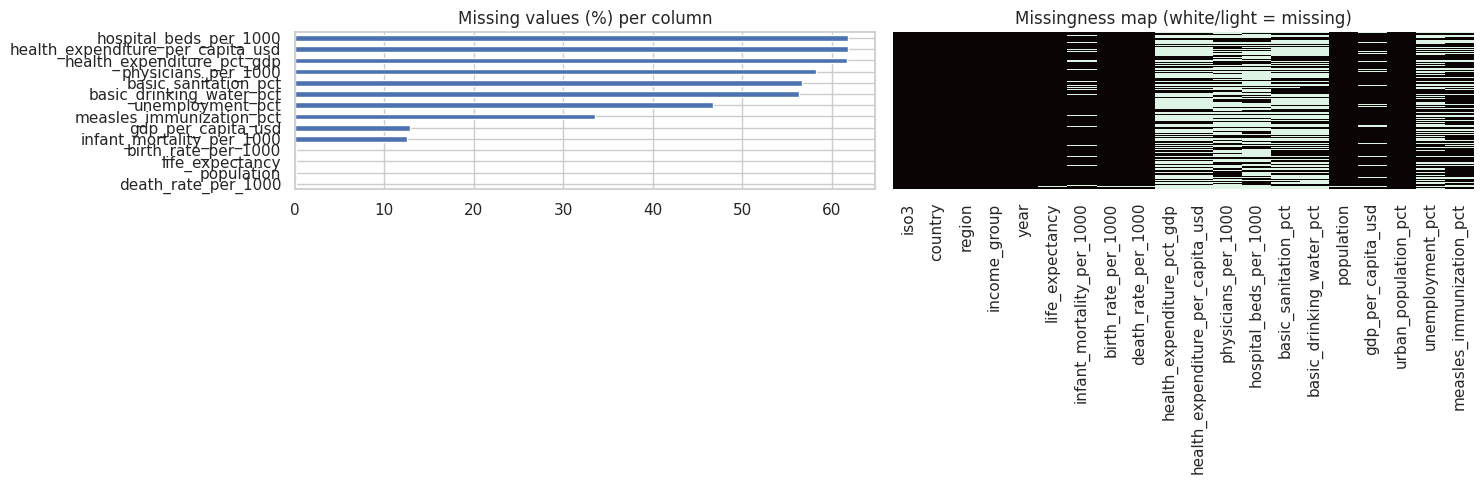

In [ ]:
miss = (df.isna().mean() * 100).sort_values(ascending=False)
display(miss.to_frame("missing_%").round(1))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
miss[miss > 0].plot.barh(ax=ax[0], color="#4c72b0"); ax[0].set_title("Missing values (%) per column"); ax[0].invert_yaxis()
sns.heatmap(df.isna().sample(1500, random_state=1).sort_index(), cbar=False, yticklabels=False, ax=ax[1], cmap="mako")
ax[1].set_title("Missingness map (white/light = missing)")
plt.tight_layout(); plt.show()

### Observations on Missing Data

Basic indicators like population, life expectancy, and birth or death rates are nearly complete. In contrast, indicators related to health systems, such as healthcare spending, physician density, hospital bed capacity, and access to clean water and sanitation, are missing for over half of the records. This missingness is concentrated in the earlier decades because systematic global surveys were not common before the year 2000.

Because the missing data depends heavily on the year and the income level of the country, the data is missing at random rather than completely at random. Consequently, we should apply imputation techniques that take time trends and country groups into account instead of using a simple global average.

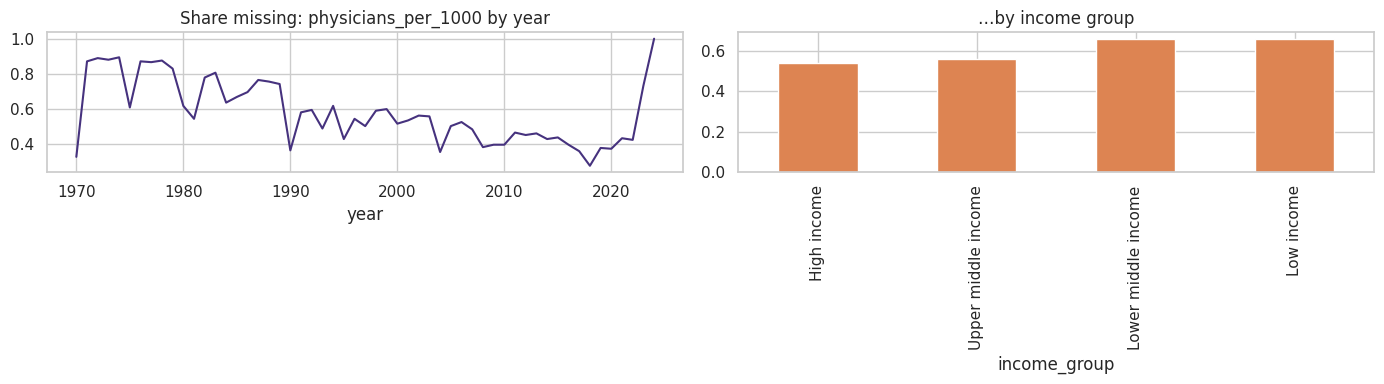

In [ ]:
# Does missingness depend on the year / income group?  (supports the MAR claim)
tmp = df.assign(miss_phys=df.physicians_per_1000.isna())
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
tmp.groupby("year").miss_phys.mean().plot(ax=ax[0]); ax[0].set_title("Share missing: physicians_per_1000 by year")
tmp.groupby("income_group").miss_phys.mean().sort_values().plot.bar(ax=ax[1], color="#dd8452"); ax[1].set_title("…by income group")
plt.tight_layout(); plt.show()

## 4. Handling Missing Values

We address missing values using the following sequence of steps:

1. We remove rows that lack life expectancy values because this is our primary target variable and we should not impute target values.
2. We apply linear interpolation within each individual country to fill short gaps over time, limiting the interpolation to five consecutive steps.
3. For any remaining missing values, we calculate and apply the median value based on the country's income group and decade.
4. If there are still empty cells, we use the global median as a final fallback.
5. We also perform K-Nearest Neighbors imputation on a sample to serve as an alternative comparison.

In [ ]:
num_cols = df.select_dtypes("number").columns.drop("year").tolist()
cat_cols = df.select_dtypes("object").columns.tolist()

# keep a snapshot for the before/after comparison and a missing-indicator flag for the most sparse columns
sparse_cols = [c for c in num_cols if df[c].isna().mean() > 0.30]
for c in sparse_cols:
    df[f"{c}_was_missing"] = df[c].isna().astype(int)
print("Missing-indicator flags added for:", sparse_cols)

before = df[num_cols].copy()
df = df.dropna(subset=["life_expectancy"]).reset_index(drop=True)
print("rows after dropping missing target:", len(df))

Missing-indicator flags added for: ['health_expenditure_pct_gdp', 'health_expenditure_per_capita_usd', 'physicians_per_1000', 'hospital_beds_per_1000', 'basic_sanitation_pct', 'basic_drinking_water_pct', 'unemployment_pct', 'measles_immunization_pct']
rows after dropping missing target: 11915


In [ ]:
df = df.sort_values(["country", "year"]).reset_index(drop=True)

# Step 2: interpolate inside every country
df[num_cols] = (df.groupby("country", group_keys=False)[num_cols]
                  .apply(lambda g: g.interpolate(method="linear", limit=5, limit_direction="both")))
print("after interpolation:\n", df[num_cols].isna().mean().mul(100).round(1).sort_values(ascending=False).head(8))

# Step 3: group median (income group x decade)
df["decade"] = (df.year // 10) * 10
for c in num_cols:
    df[c] = df[c].fillna(df.groupby(["income_group", "decade"])[c].transform("median"))
# Step 4: global median
df[num_cols] = SimpleImputer(strategy="median").fit_transform(df[num_cols])
print("\nremaining NaN:", int(df[num_cols].isna().sum().sum()))

after interpolation:
 health_expenditure_pct_gdp           52.2
health_expenditure_per_capita_usd    52.2
basic_sanitation_pct                 47.0
basic_drinking_water_pct             46.9
unemployment_pct                     38.8
hospital_beds_per_1000               25.7
measles_immunization_pct             25.3
physicians_per_1000                  15.8
dtype: float64

remaining NaN: 0


KNN imputation finished; remaining NaN: 0


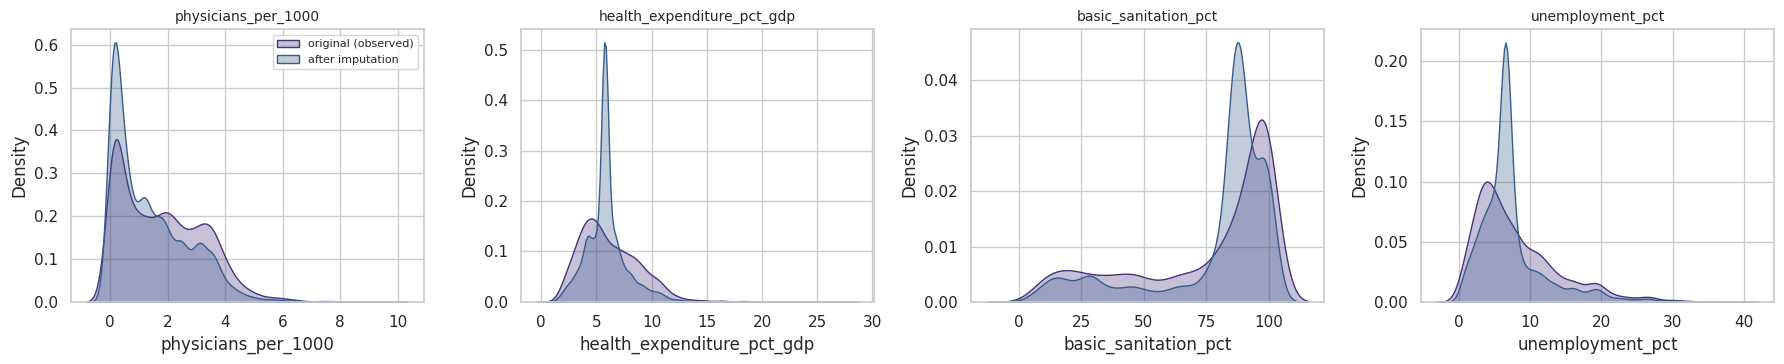

In [ ]:
# Alternative: KNN imputation on a scaled sample (k=5) for comparison
sample = before.dropna(subset=["life_expectancy"]).sample(2000, random_state=0)
knn = pd.DataFrame(KNNImputer(n_neighbors=5).fit_transform(StandardScaler().fit_transform(sample)),
                   columns=sample.columns)
print("KNN imputation finished; remaining NaN:", int(knn.isna().sum().sum()))

# Distribution check – imputation should not distort the original distribution
cols_show = ["physicians_per_1000", "health_expenditure_pct_gdp", "basic_sanitation_pct", "unemployment_pct"]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, c in zip(axes, cols_show):
    sns.kdeplot(before[c].dropna(), ax=ax, label="original (observed)", fill=True, alpha=.3)
    sns.kdeplot(df[c], ax=ax, label="after imputation", fill=True, alpha=.3)
    ax.set_title(c, fontsize=10)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 5. Outlier Detection and Treatment

We use the Interquartile Range rule to identify outliers across all numerical columns and visualize them using box plots. For columns where extreme values represent data collection issues rather than genuine trends, we cap the values at the 1st and 99th percentiles. We do not cap the population column because its extreme values represent real differences in country sizes, such as India and China. We will handle population skewness later using a logarithmic transformation.

,outliers,pct
basic_sanitation_pct,2060,17.3
basic_drinking_water_pct,1979,16.6
health_expenditure_per_capita_usd,1753,14.7
population,1563,13.1
gdp_per_capita_usd,1451,12.2
unemployment_pct,1384,11.6
health_expenditure_pct_gdp,1051,8.8
death_rate_per_1000,668,5.6
hospital_beds_per_1000,450,3.8
infant_mortality_per_1000,408,3.4


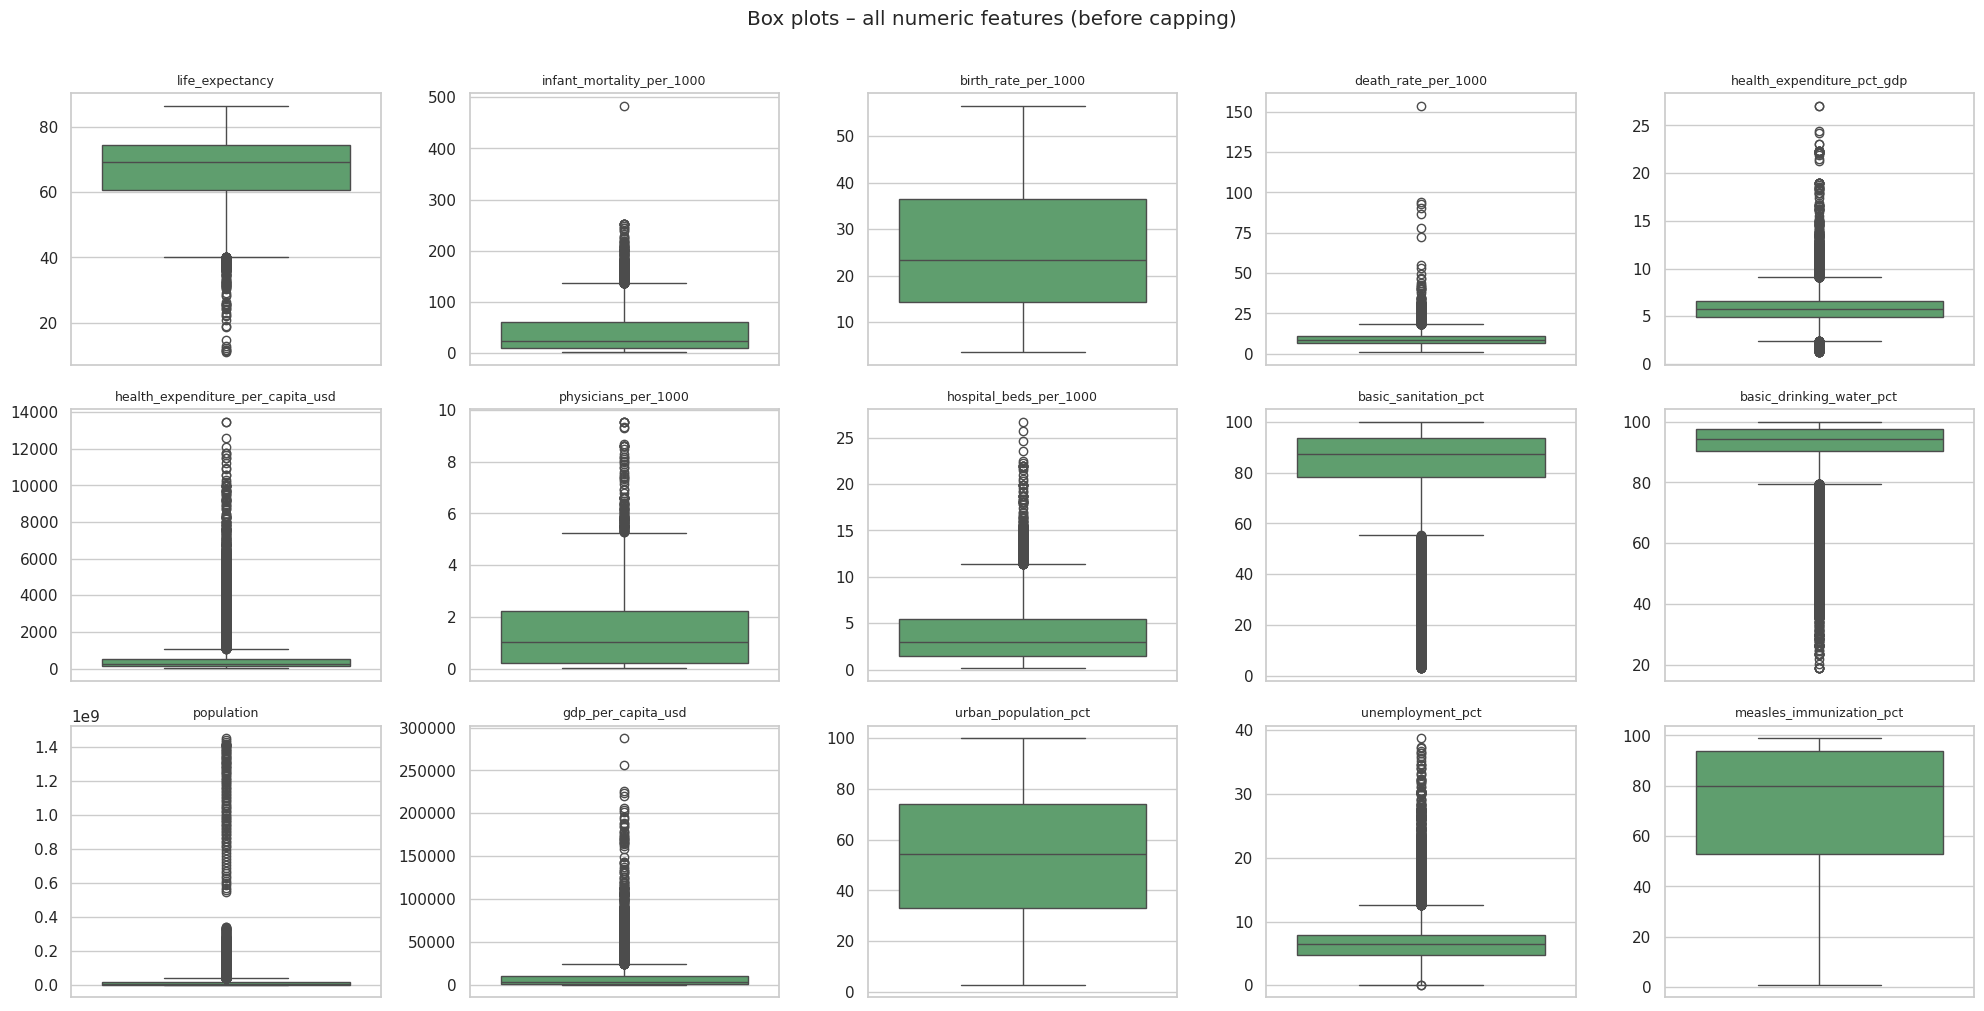

In [ ]:
plot_cols = [c for c in num_cols]
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum()
out = pd.DataFrame({"outliers": [iqr_outliers(df[c]) for c in plot_cols]}, index=plot_cols)
out["pct"] = (out.outliers / len(df) * 100).round(1)
display(out.sort_values("pct", ascending=False))

fig, axes = plt.subplots(3, 5, figsize=(20, 10))
for ax, c in zip(axes.ravel(), plot_cols):
    sns.boxplot(y=df[c], ax=ax, color="#55a868"); ax.set_title(c, fontsize=9); ax.set_ylabel("")
plt.suptitle("Box plots – all numeric features (before capping)", y=1.01); plt.tight_layout(); plt.show()

In [ ]:
cap_cols = [c for c in num_cols if c != "population"]
df_capped = df.copy()
for c in cap_cols:
    lo, hi = df[c].quantile([.01, .99]); df_capped[c] = df[c].clip(lo, hi)

chk = ["health_expenditure_per_capita_usd", "gdp_per_capita_usd", "physicians_per_1000"]
display(pd.concat({"before": df[chk].describe().loc[["min", "max", "std"]],
                   "after capping": df_capped[chk].describe().loc[["min", "max", "std"]]}).round(2))
df = df_capped

health_expenditure_per_capita_usd  gdp_per_capita_usd  \
before        min                               4.18               20.72   
              max                           13473.19           288001.57   
              std                            1245.24            19080.75   
after capping min                              10.07              118.48   
              max                            6621.30            89861.65   
              std                            1121.29            16397.68   

                   physicians_per_1000  
before        min                 0.00  
              max                 9.54  
              std                 1.34  
after capping min                 0.02  
              max                 5.17  
              std                 1.29

## 6. Exploratory Data Analysis

### 6.1 Univariate Analysis of Numerical Variables

We examine individual numerical variables using histograms, kernel density plots, and violin plots.

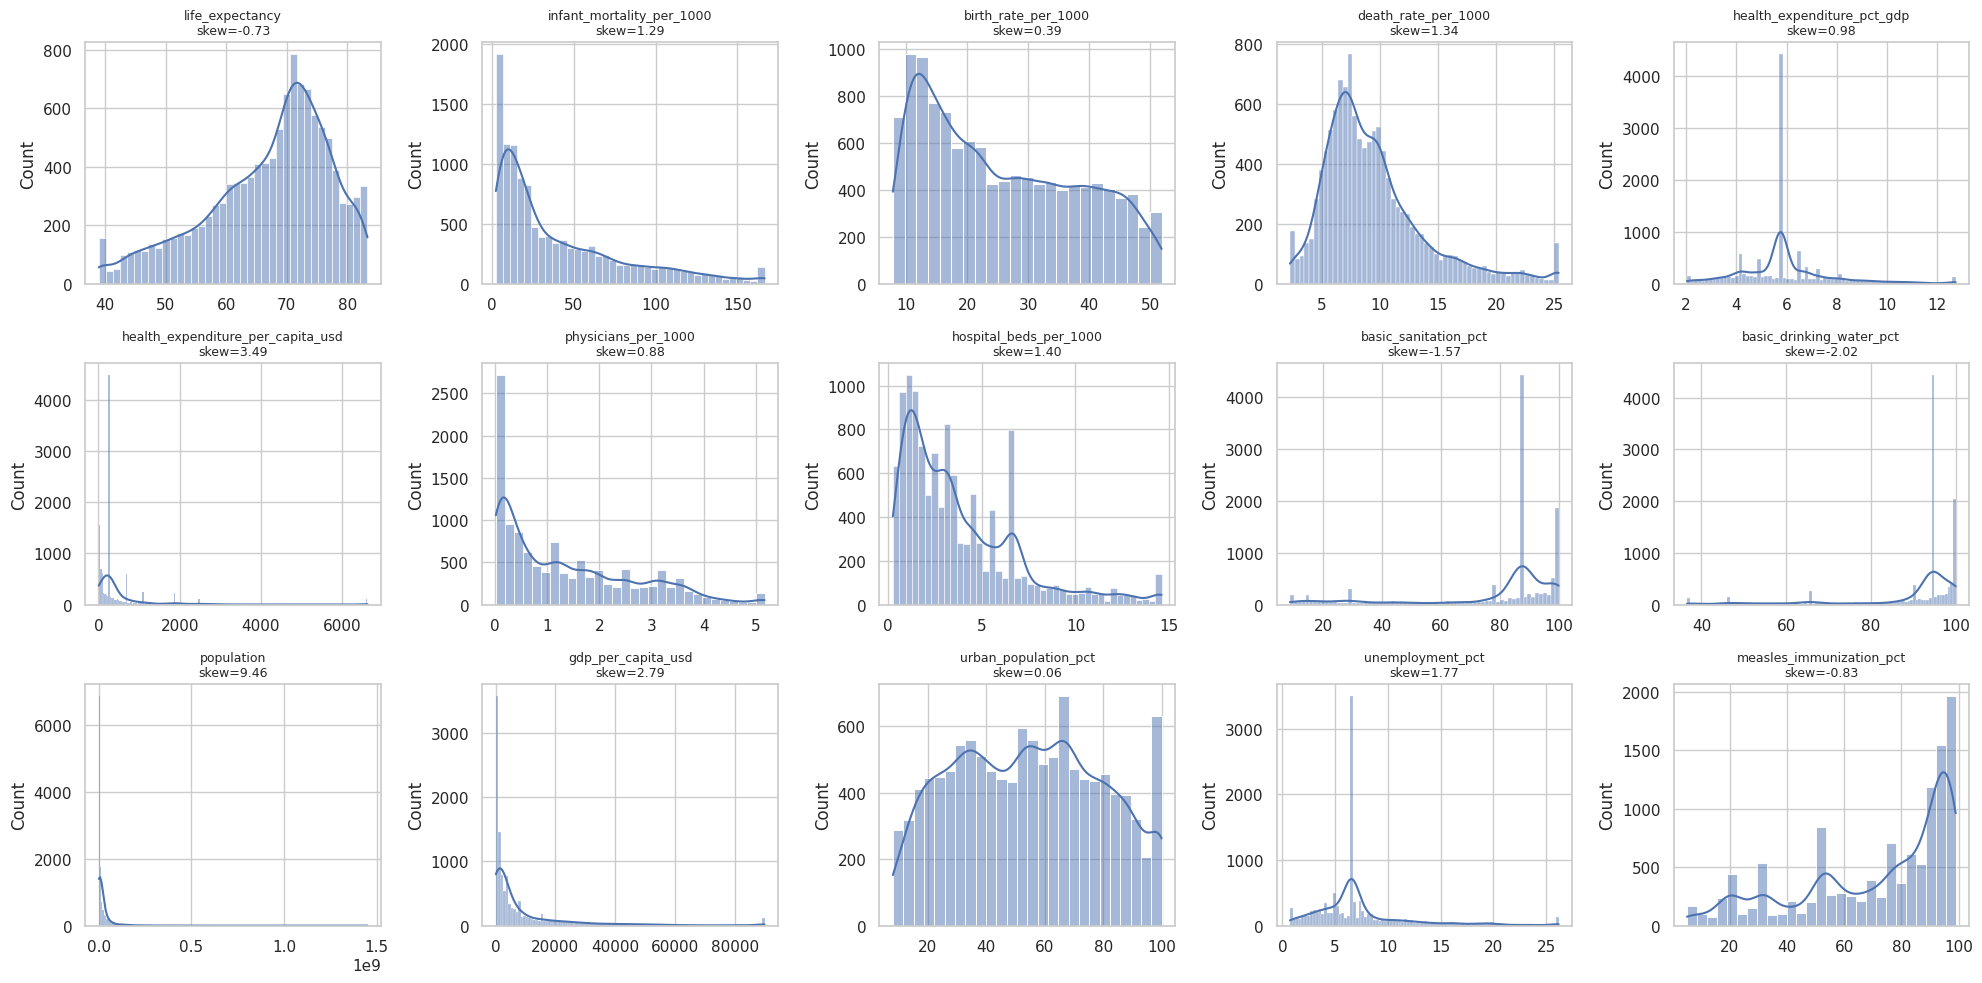

In [ ]:
fig, axes = plt.subplots(3, 5, figsize=(20, 10))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], kde=True, ax=ax, color="#4c72b0"); ax.set_title(f"{c}\nskew={df[c].skew():.2f}", fontsize=9); ax.set_xlabel("")
plt.tight_layout(); plt.show()

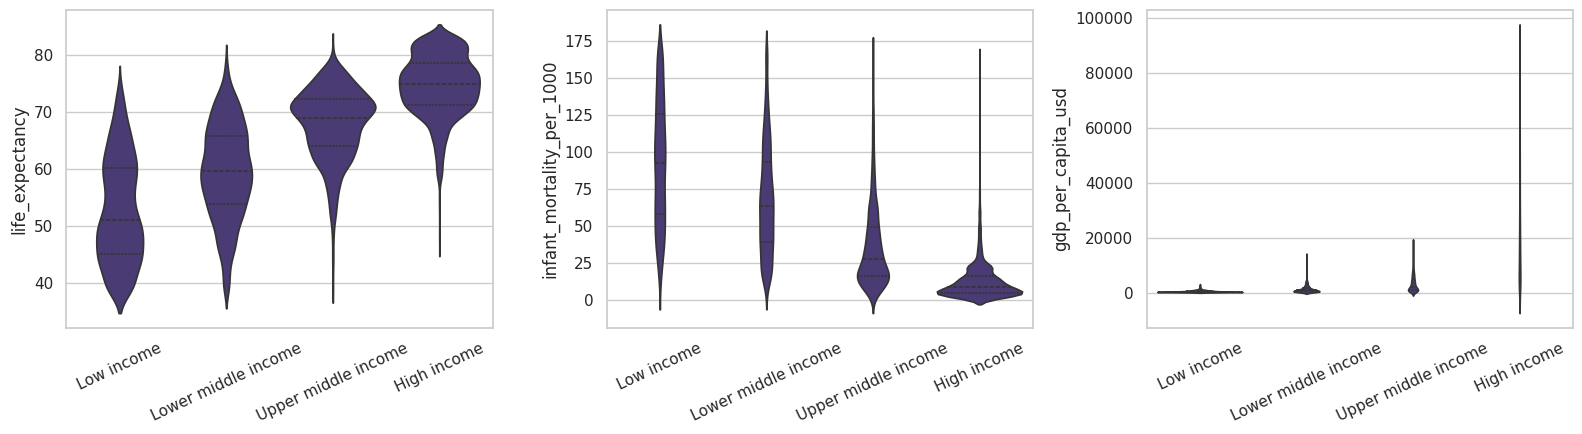

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c in zip(axes, ["life_expectancy", "infant_mortality_per_1000", "gdp_per_capita_usd"]):
    sns.violinplot(data=df, y=c, x="income_group",
                   order=["Low income", "Lower middle income", "Upper middle income", "High income"], ax=ax, inner="quartile")
    ax.tick_params(axis="x", rotation=25); ax.set_xlabel("")
plt.tight_layout(); plt.show()

### 6.2 Univariate Analysis of Categorical Variables

We examine categorical distributions using count plots and pie charts.

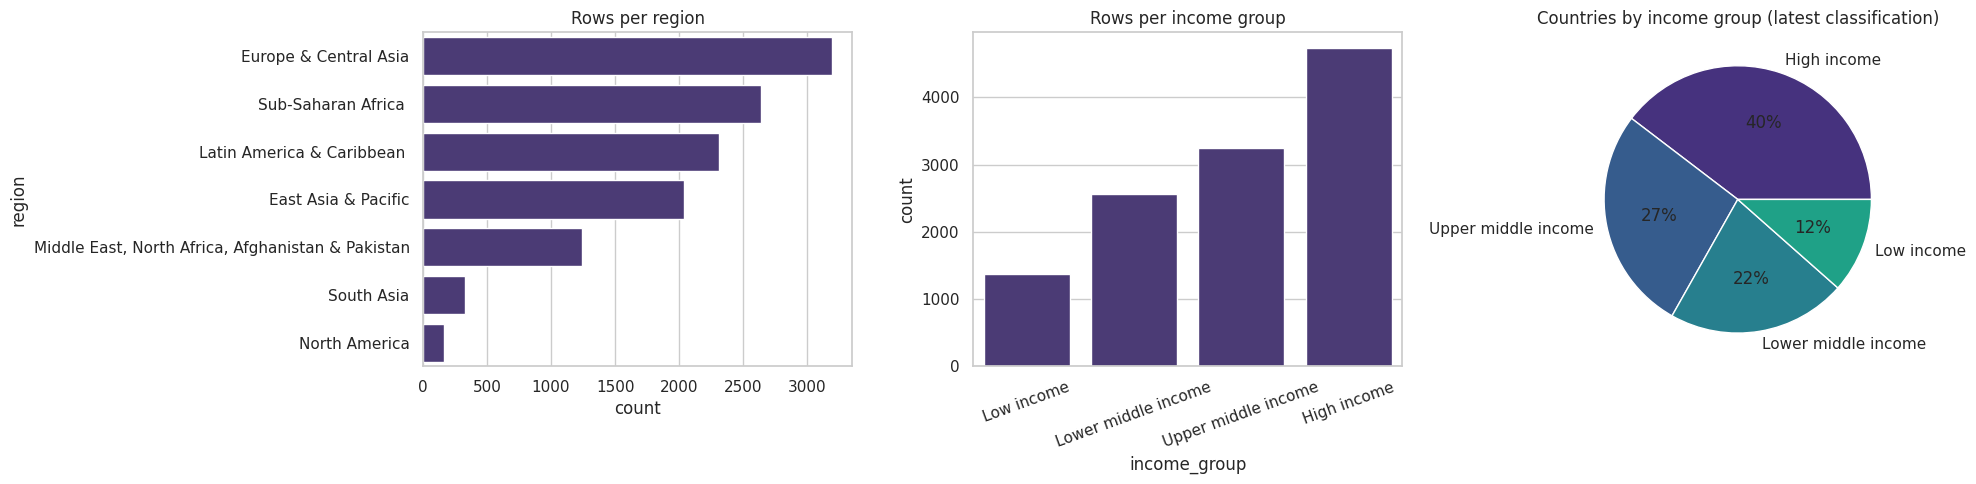

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.countplot(data=df, y="region", order=df.region.value_counts().index, ax=axes[0]); axes[0].set_title("Rows per region")
sns.countplot(data=df, x="income_group", order=["Low income","Lower middle income","Upper middle income","High income"], ax=axes[1])
axes[1].set_title("Rows per income group"); axes[1].tick_params(axis="x", rotation=20)
df.groupby("country").income_group.first().value_counts().plot.pie(autopct="%1.0f%%", ax=axes[2]); axes[2].set_ylabel("")
axes[2].set_title("Countries by income group (latest classification)")
plt.tight_layout(); plt.show()

### 6.3 Bivariate Analysis: Numerical vs Categorical

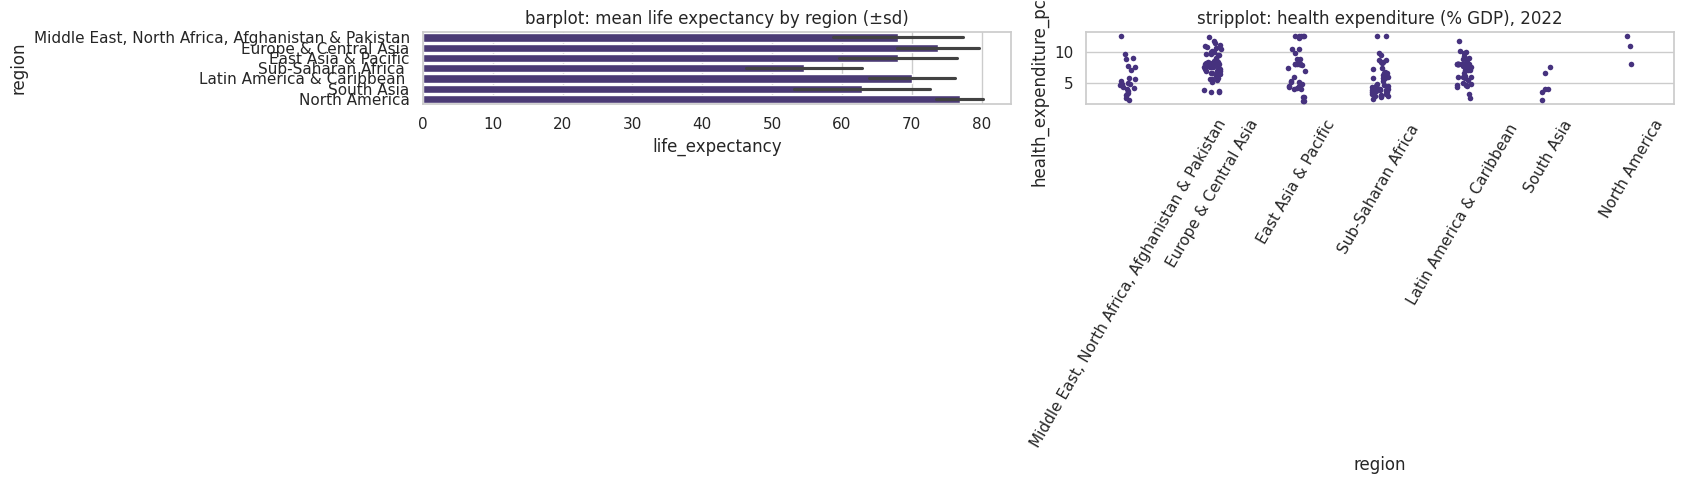

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
sns.barplot(data=df, y="region", x="life_expectancy", ax=axes[0], errorbar="sd"); axes[0].set_title("barplot: mean life expectancy by region (±sd)")
sns.stripplot(data=df[df.year == 2022], x="region", y="health_expenditure_pct_gdp", ax=axes[1], size=4)
axes[1].set_title("stripplot: health expenditure (% GDP), 2022"); axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

### 6.4 Bivariate Analysis: Numerical vs Numerical

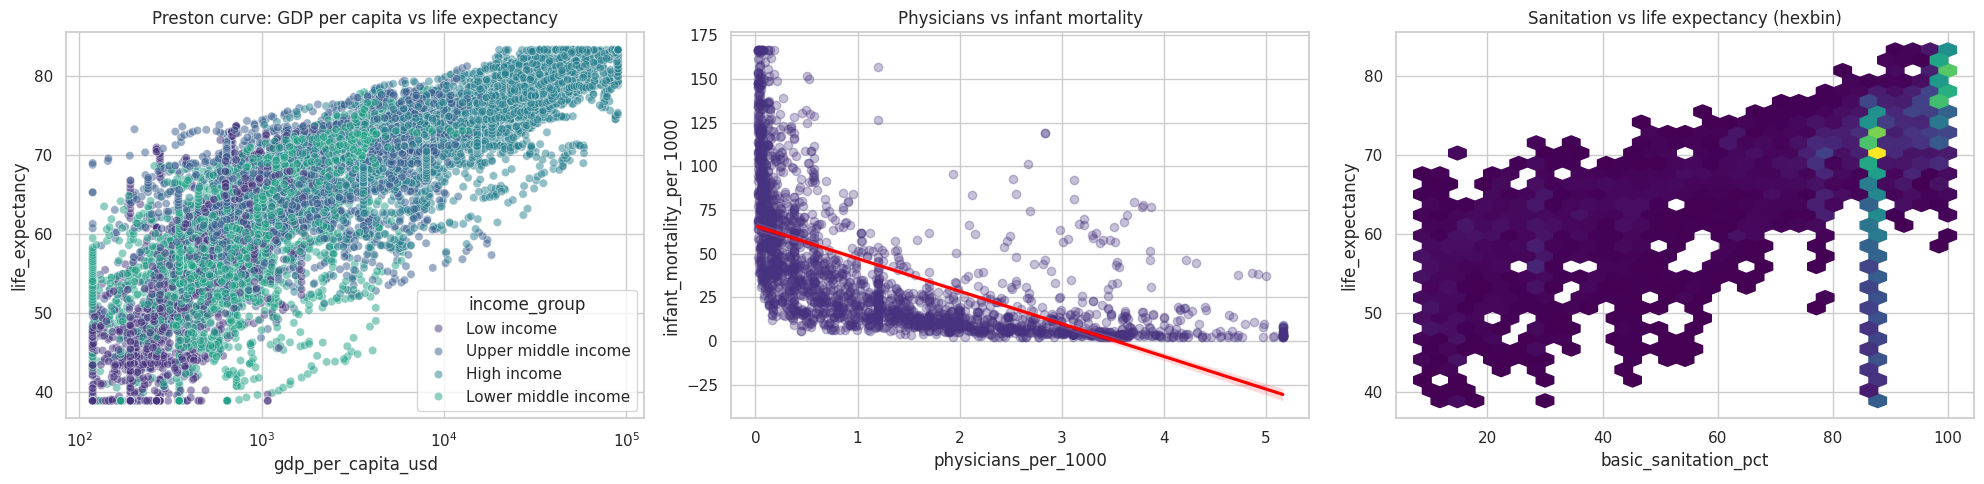

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.scatterplot(data=df, x="gdp_per_capita_usd", y="life_expectancy", hue="income_group", alpha=.5, ax=axes[0]); axes[0].set_xscale("log")
axes[0].set_title("Preston curve: GDP per capita vs life expectancy")
sns.regplot(data=df.sample(2500, random_state=1), x="physicians_per_1000", y="infant_mortality_per_1000",
            scatter_kws={"alpha": .3}, line_kws={"color": "red"}, ax=axes[1]); axes[1].set_title("Physicians vs infant mortality")
axes[2].hexbin(df.basic_sanitation_pct, df.life_expectancy, gridsize=30, cmap="viridis", mincnt=1)
axes[2].set_xlabel("basic_sanitation_pct"); axes[2].set_ylabel("life_expectancy"); axes[2].set_title("Sanitation vs life expectancy (hexbin)")
plt.tight_layout(); plt.show()

### 6.5 Time Series Trends

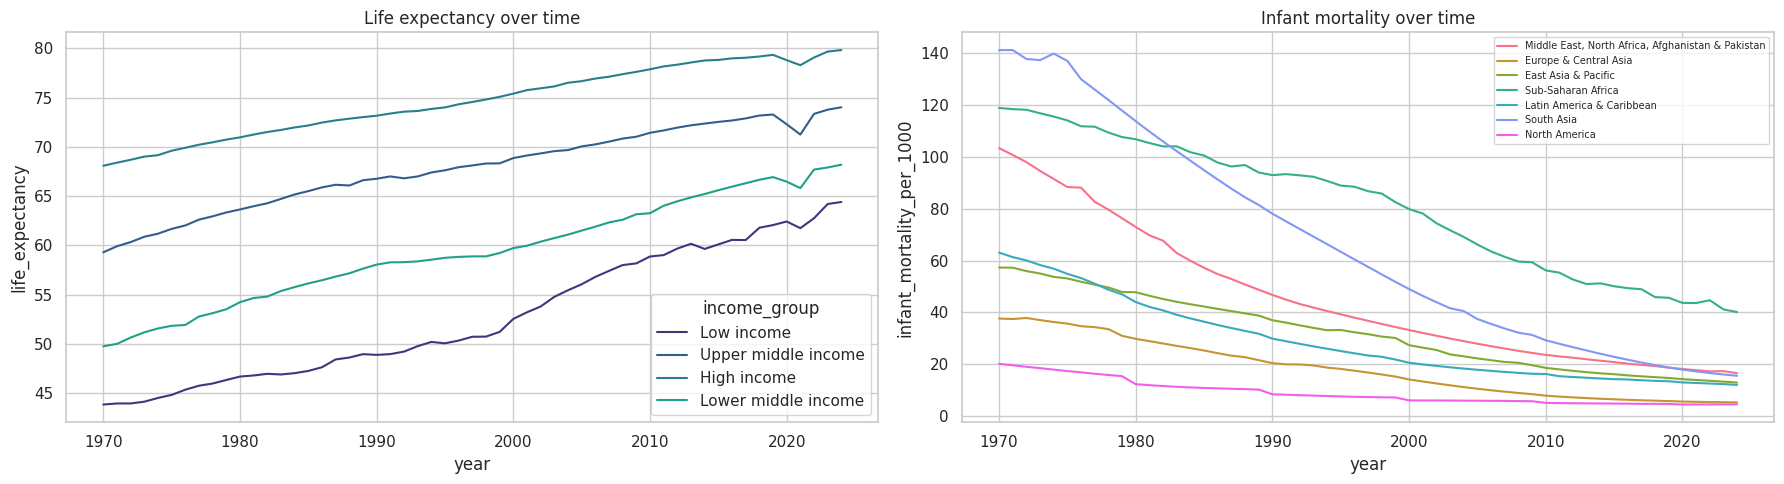

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
sns.lineplot(data=df, x="year", y="life_expectancy", hue="income_group", errorbar=None, ax=axes[0]); axes[0].set_title("Life expectancy over time")
sns.lineplot(data=df, x="year", y="infant_mortality_per_1000", hue="region", errorbar=None, ax=axes[1]); axes[1].set_title("Infant mortality over time")
axes[1].legend(fontsize=7); plt.tight_layout(); plt.show()

### 6.6 Correlation Analysis

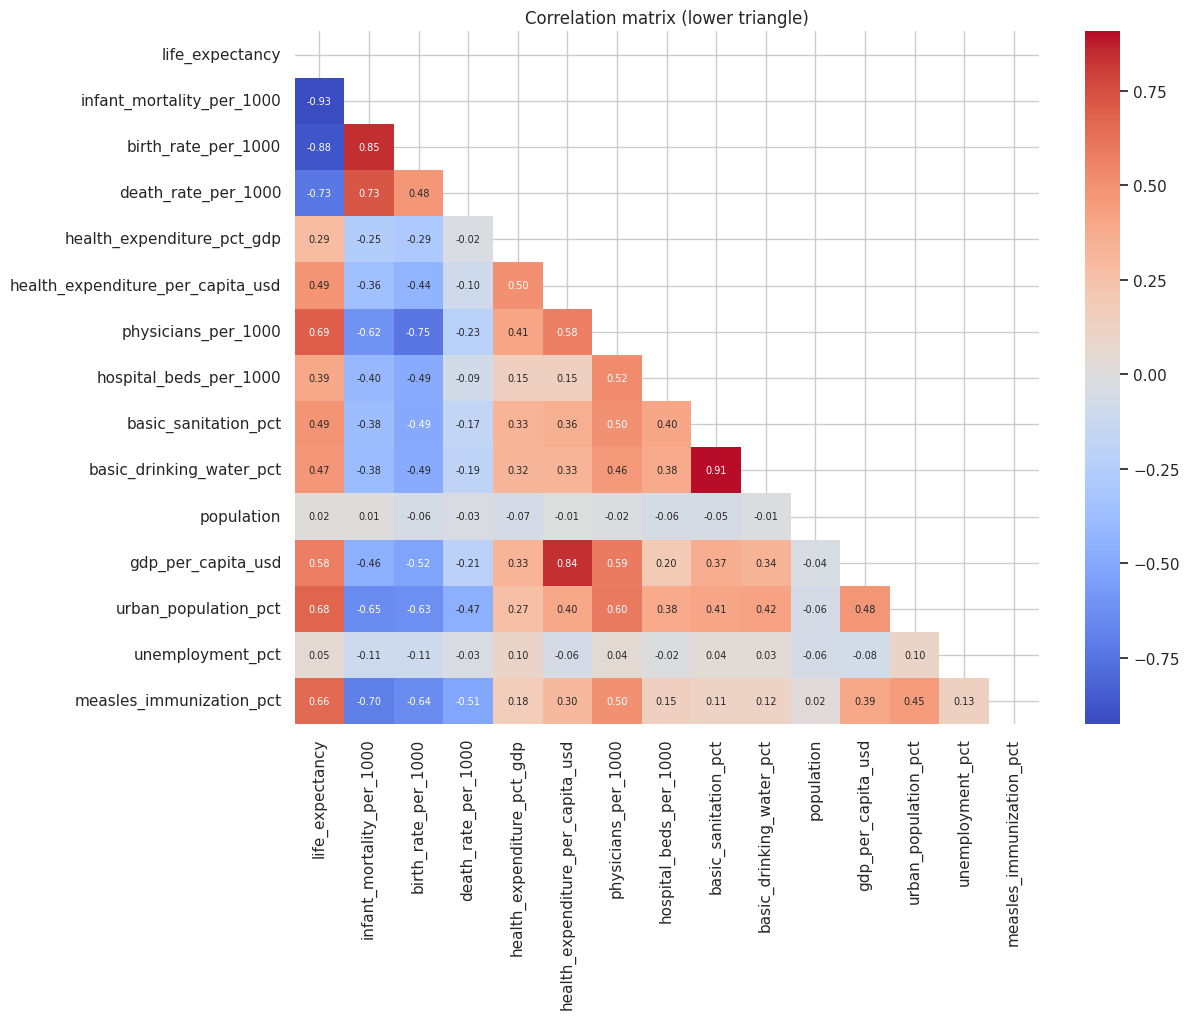

In [ ]:
corr = df[num_cols].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, mask=np.triu(np.ones_like(corr, bool)), annot_kws={"size": 7})
plt.title("Correlation matrix (lower triangle)"); plt.show()

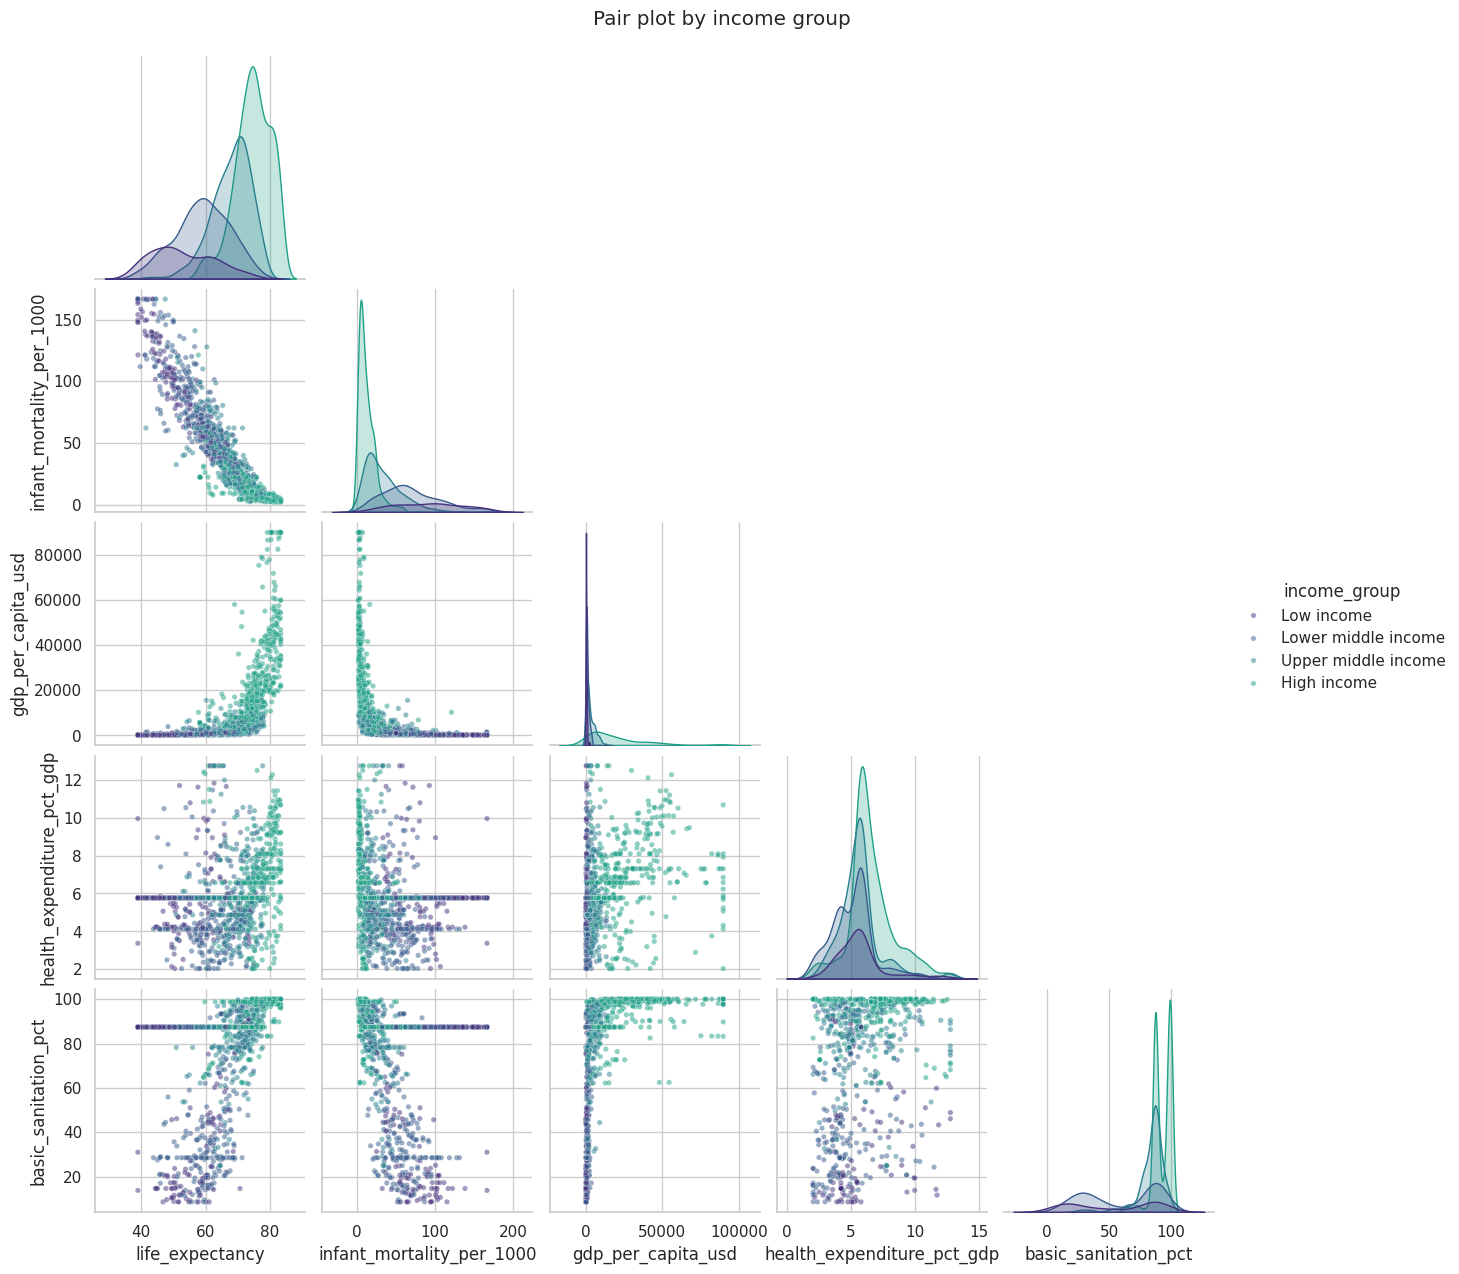

In [ ]:
pp_cols = ["life_expectancy", "infant_mortality_per_1000", "gdp_per_capita_usd", "health_expenditure_pct_gdp", "basic_sanitation_pct"]
g = sns.pairplot(df.sample(1500, random_state=0), vars=pp_cols, hue="income_group", corner=True, plot_kws={"alpha": .5, "s": 15},
                 hue_order=["Low income","Lower middle income","Upper middle income","High income"])
g.fig.suptitle("Pair plot by income group", y=1.02); plt.show()

### Key Findings from Exploration

Life expectancy increases rapidly with economic development and then flattens out, which represents the Preston curve. Infant mortality rates, access to sanitation, and physician density differ clearly across country income groups. Several indicators, such as gross domestic product, healthcare spending, and population size, are highly skewed to the right and are good candidates for logarithmic transformations.

## 6.7 Data Visualization Gallery

This section displays various unique plot types using Matplotlib and Seaborn. Plot types shown in previous sections are not repeated here.

### 6.7.1 Seaborn: Advanced Distribution and Categorical Plots

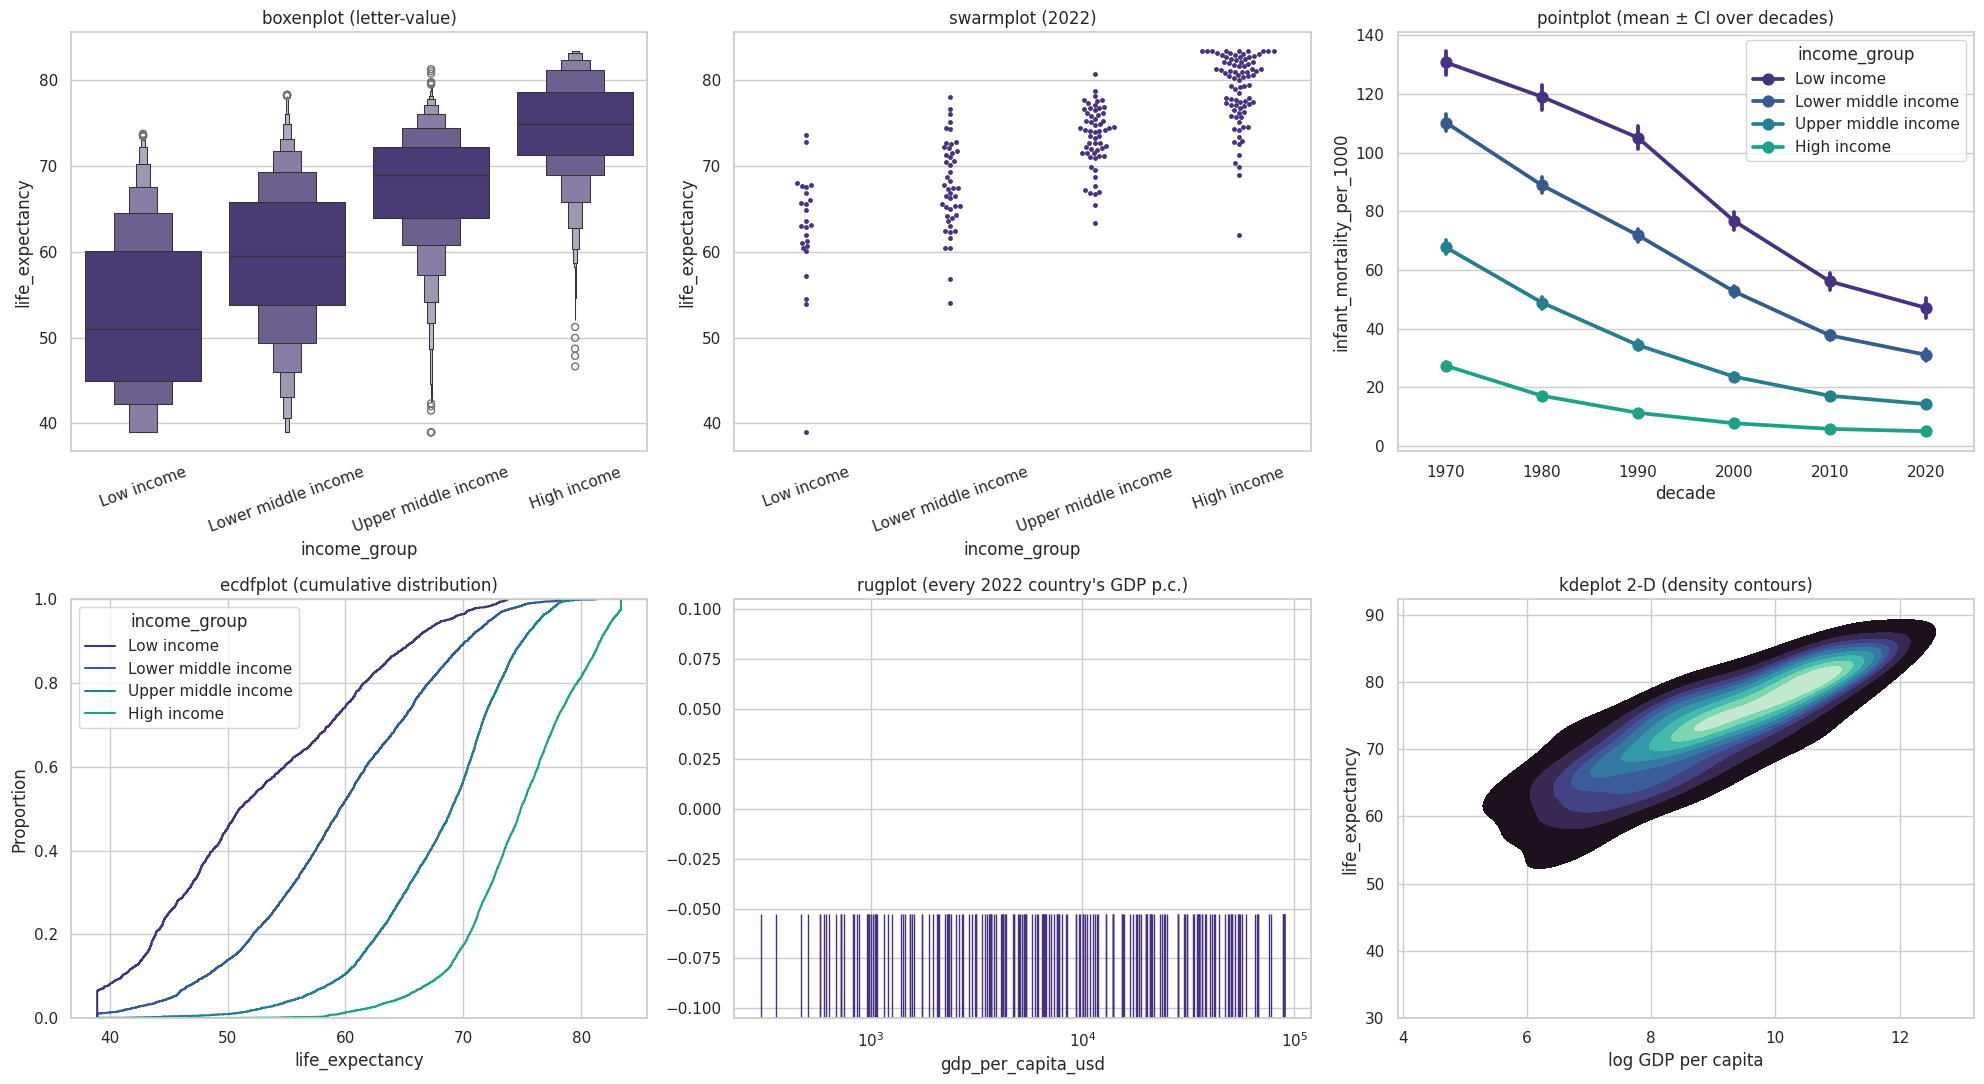

In [ ]:
snap = df[df.year == 2022].copy()
order = ["Low income", "Lower middle income", "Upper middle income", "High income"]
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
sns.boxenplot(data=df, x="income_group", y="life_expectancy", order=order, ax=axes[0, 0]); axes[0, 0].set_title("boxenplot (letter-value)")
sns.swarmplot(data=snap, x="income_group", y="life_expectancy", order=order, size=3.5, ax=axes[0, 1]); axes[0, 1].set_title("swarmplot (2022)")
sns.pointplot(data=df, x="era" if "era" in df else "decade", y="infant_mortality_per_1000", hue="income_group", hue_order=order, ax=axes[0, 2])
axes[0, 2].set_title("pointplot (mean ± CI over decades)")
sns.ecdfplot(data=df, x="life_expectancy", hue="income_group", hue_order=order, ax=axes[1, 0]); axes[1, 0].set_title("ecdfplot (cumulative distribution)")
sns.rugplot(data=snap, x="gdp_per_capita_usd", height=.25, ax=axes[1, 1]); axes[1, 1].set_xscale("log"); axes[1, 1].set_title("rugplot (every 2022 country's GDP p.c.)")
sns.kdeplot(data=snap, x="log_gdp" if "log_gdp" in snap else np.log1p(snap.gdp_per_capita_usd), y=snap.life_expectancy, fill=True, cmap="mako", levels=10, ax=axes[1, 2])
axes[1, 2].set_title("kdeplot 2-D (density contours)"); axes[1, 2].set_xlabel("log GDP per capita")
for ax in axes[0, :2]: ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

### 6.7.2 Seaborn: Multi-Plot Grids and Relational Visualizations

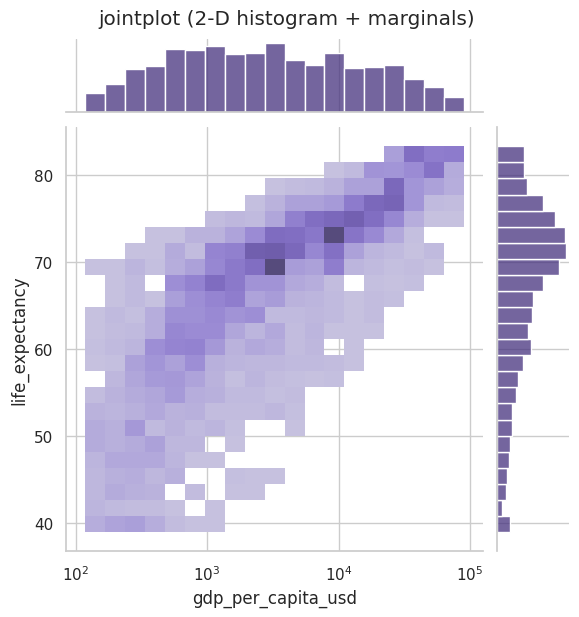

In [ ]:
sns.jointplot(data=df.sample(3000, random_state=3), x="gdp_per_capita_usd", y="life_expectancy", kind="hist", log_scale=(True, False), height=6)
plt.suptitle("jointplot (2-D histogram + marginals)", y=1.02); plt.show()

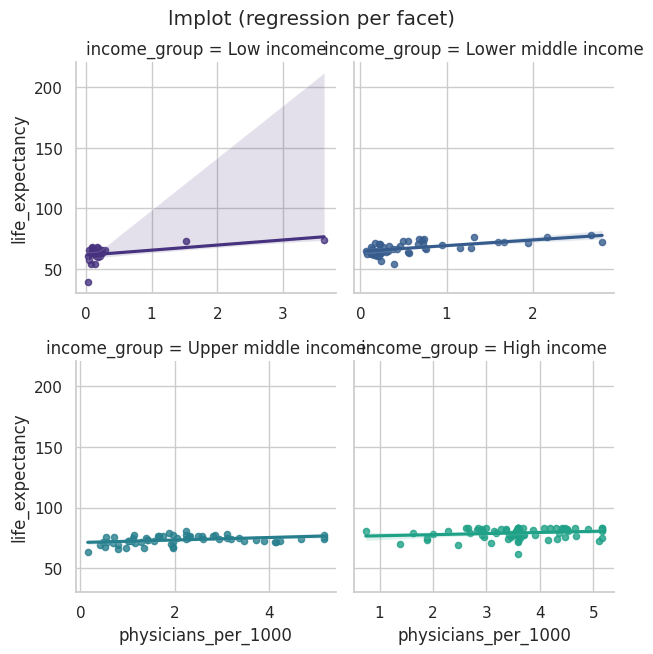

In [ ]:
sns.lmplot(data=snap, x="physicians_per_1000", y="life_expectancy", hue="income_group", col="income_group", col_wrap=2, hue_order=order,
           col_order=order, height=3.2, scatter_kws={"s": 20}, facet_kws={"sharex": False})
plt.suptitle("lmplot (regression per facet)", y=1.02); plt.show()

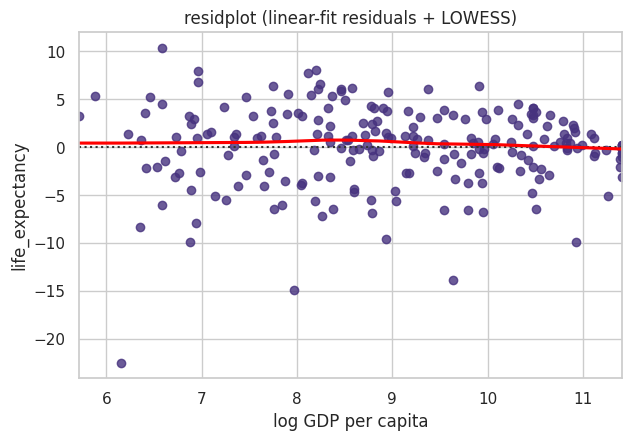

In [ ]:
plt.figure(figsize=(7, 4.5))
sns.residplot(data=snap, x="log_gdp" if "log_gdp" in snap else np.log1p(snap.gdp_per_capita_usd), y="life_expectancy", lowess=True, line_kws={"color": "red"})
plt.title("residplot (linear-fit residuals + LOWESS)"); plt.xlabel("log GDP per capita"); plt.show()

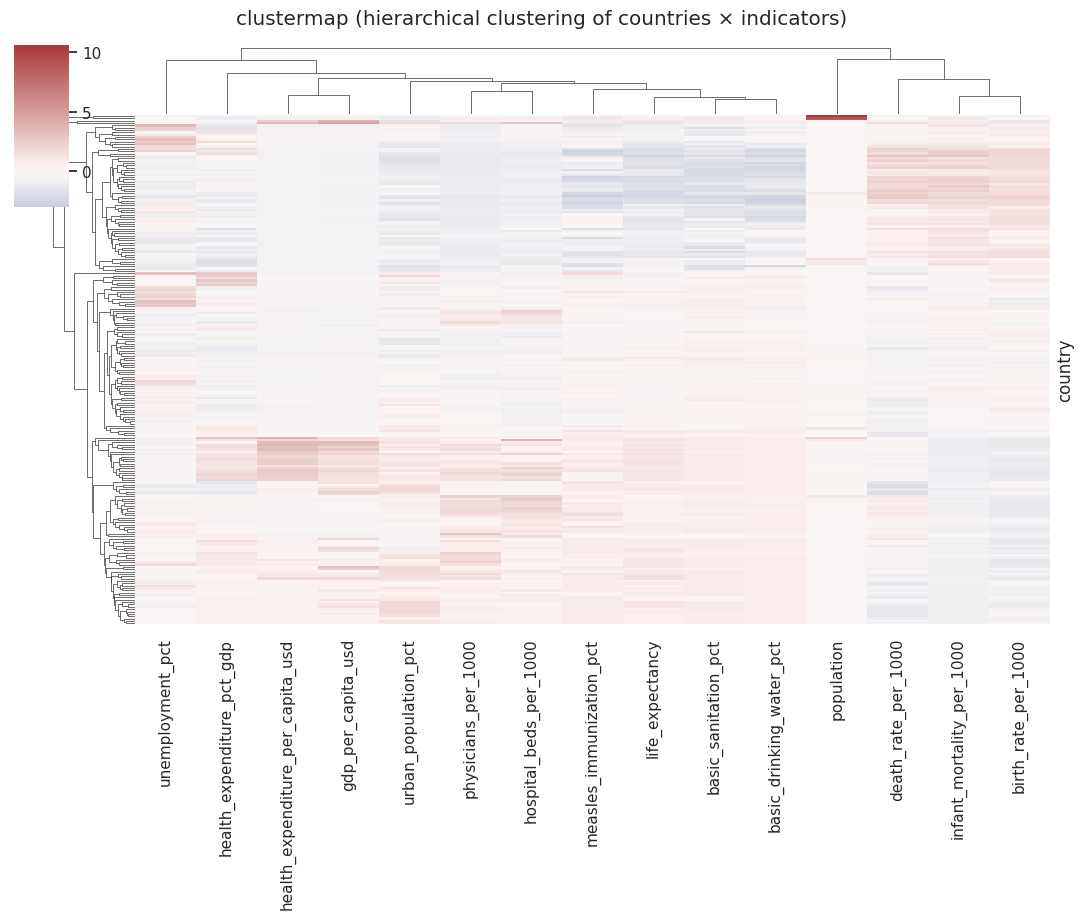

In [ ]:
cm_data = df.groupby("country")[num_cols].mean().dropna()
sns.clustermap(StandardScaler().fit_transform(cm_data[num_cols]).T if False else (cm_data - cm_data.mean()) / cm_data.std(),
               cmap="vlag", center=0, figsize=(11, 9), yticklabels=False, dendrogram_ratio=.12)
plt.suptitle("clustermap (hierarchical clustering of countries × indicators)", y=1.02); plt.show()

### 6.7.3 Matplotlib: Basic Chart Elements and Uncertainty Bands

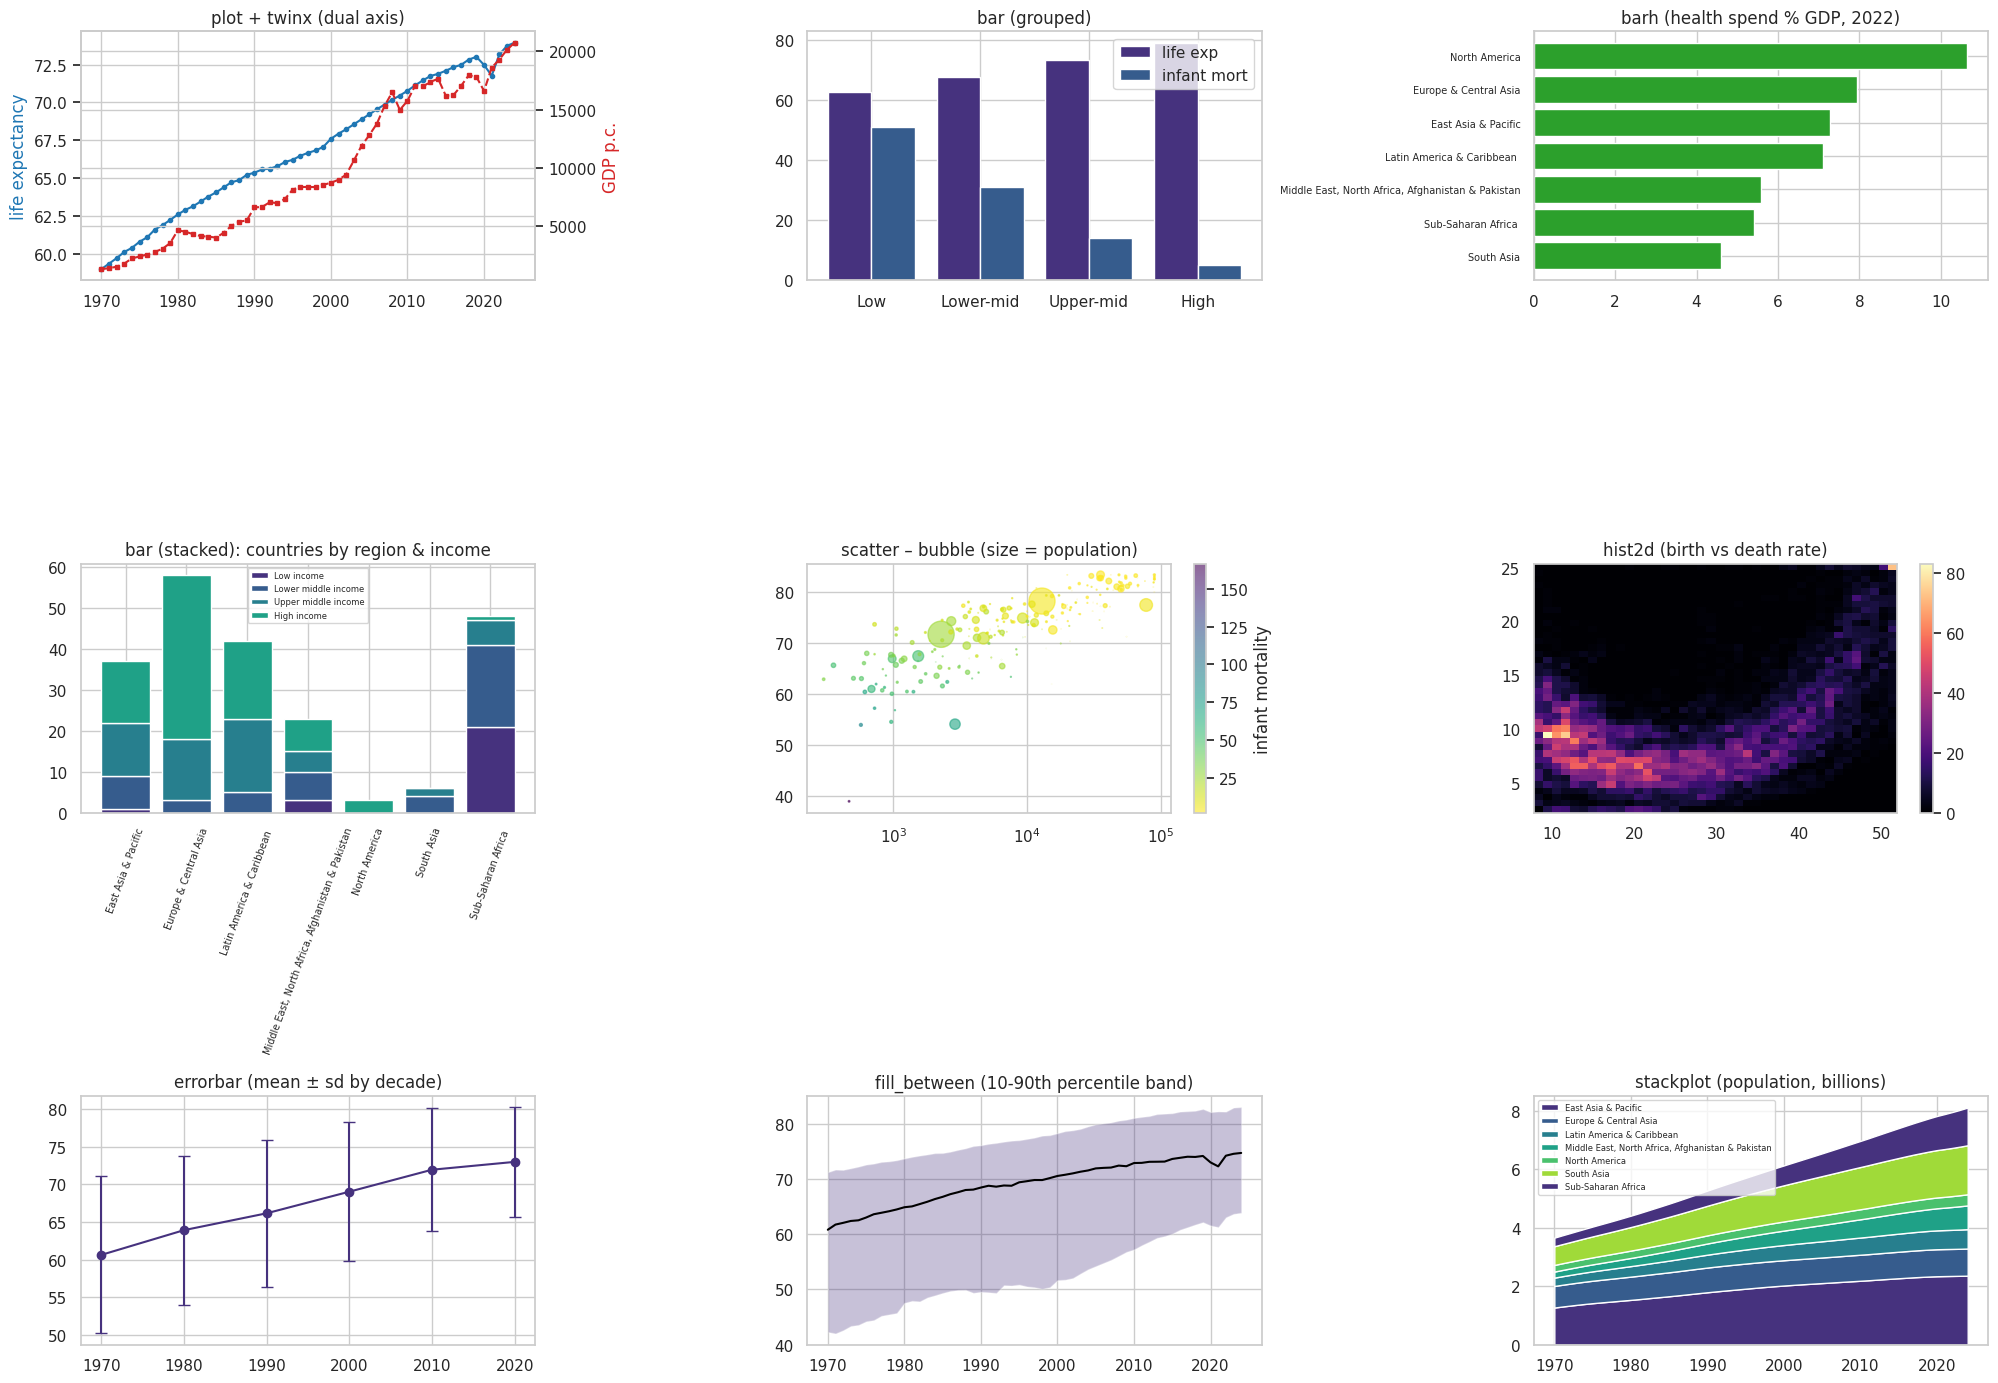

In [ ]:
reg = df.groupby("region")
yrs = df.groupby("year")
fig, axes = plt.subplots(3, 3, figsize=(20, 14))
# 1 line with markers + twin y-axis
w = yrs[["life_expectancy", "gdp_per_capita_usd"]].mean(); ax = axes[0, 0]; ax.plot(w.index, w.life_expectancy, "o-", ms=3, color="tab:blue")
ax.set_ylabel("life expectancy", color="tab:blue"); ax2 = ax.twinx(); ax2.plot(w.index, w.gdp_per_capita_usd, "s--", ms=3, color="tab:red")
ax2.set_ylabel("GDP p.c.", color="tab:red"); ax.set_title("plot + twinx (dual axis)")
# 2 grouped bar
t = snap.groupby("income_group")[["life_expectancy", "infant_mortality_per_1000"]].mean().reindex(order); x = np.arange(4)
axes[0, 1].bar(x - .2, t.life_expectancy, .4, label="life exp"); axes[0, 1].bar(x + .2, t.infant_mortality_per_1000, .4, label="infant mort")
axes[0, 1].set_xticks(x); axes[0, 1].set_xticklabels(["Low", "Lower-mid", "Upper-mid", "High"]); axes[0, 1].legend(); axes[0, 1].set_title("bar (grouped)")
# 3 horizontal bar
r = snap.groupby("region").health_expenditure_pct_gdp.mean().sort_values(); axes[0, 2].barh(r.index, r.values, color="tab:green"); axes[0, 2].set_title("barh (health spend % GDP, 2022)")
axes[0, 2].tick_params(axis="y", labelsize=7)
# 4 stacked bar
c = snap.groupby(["region", "income_group"]).size().unstack(fill_value=0)[order]; bottom = np.zeros(len(c))
for col in order: axes[1, 0].bar(c.index, c[col], bottom=bottom, label=col); bottom += c[col].values
axes[1, 0].tick_params(axis="x", rotation=70, labelsize=7); axes[1, 0].legend(fontsize=6); axes[1, 0].set_title("bar (stacked): countries by region & income")
# 5 bubble scatter
sc = axes[1, 1].scatter(snap.gdp_per_capita_usd, snap.life_expectancy, s=snap.population / 4e6, c=snap.infant_mortality_per_1000, cmap="viridis_r", alpha=.6)
axes[1, 1].set_xscale("log"); plt.colorbar(sc, ax=axes[1, 1], label="infant mortality"); axes[1, 1].set_title("scatter – bubble (size = population)")
# 6 2-D histogram
h = axes[1, 2].hist2d(df.birth_rate_per_1000, df.death_rate_per_1000, bins=40, cmap="magma"); plt.colorbar(h[3], ax=axes[1, 2]); axes[1, 2].set_title("hist2d (birth vs death rate)")
# 7 errorbar
m = df.groupby("decade").life_expectancy.agg(["mean", "std"]); axes[2, 0].errorbar(m.index, m["mean"], yerr=m["std"], fmt="o-", capsize=4); axes[2, 0].set_title("errorbar (mean ± sd by decade)")
# 8 fill_between
q = yrs.life_expectancy.quantile([.1, .5, .9]).unstack(); axes[2, 1].plot(q.index, q[.5], color="k"); axes[2, 1].fill_between(q.index, q[.1], q[.9], alpha=.3)
axes[2, 1].set_title("fill_between (10-90th percentile band)")
# 9 stackplot
sp = df.groupby(["year", "region"]).population.sum().unstack() / 1e9; axes[2, 2].stackplot(sp.index, sp.T.values, labels=sp.columns); axes[2, 2].legend(fontsize=6, loc="upper left")
axes[2, 2].set_title("stackplot (population, billions)")
plt.tight_layout(); plt.show()

### 6.7.4 Matplotlib: Specialized Engineering and Mathematical Plots

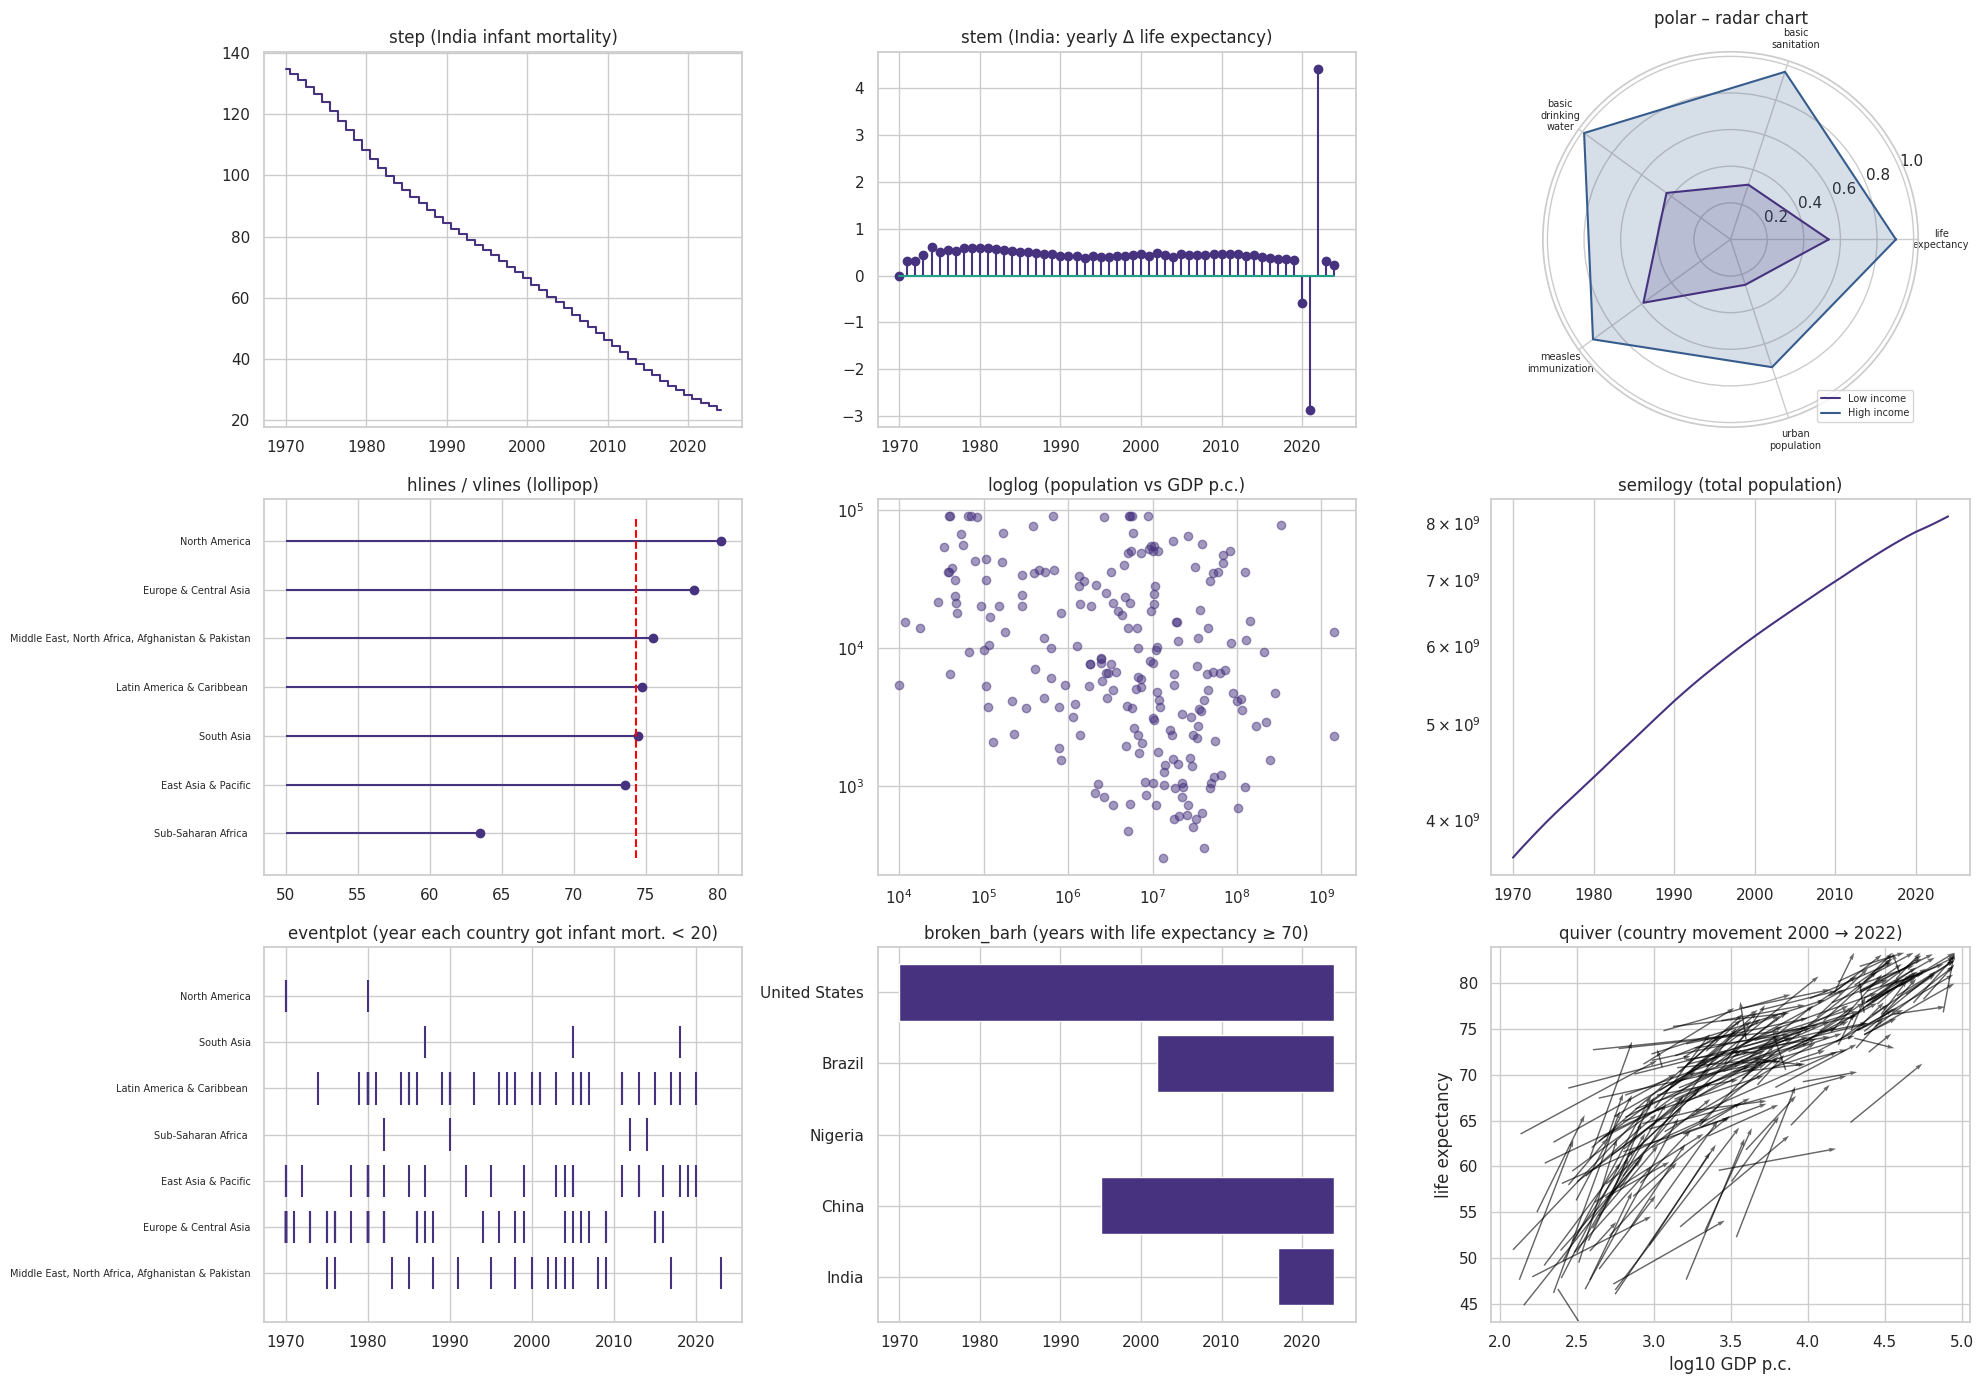

In [ ]:
from scipy.ndimage import gaussian_filter
ind = {"India": "India", "China": "China", "Nigeria": "Nigeria", "Brazil": "Brazil", "United States": "United States"}
fig = plt.figure(figsize=(20, 14))
# 1 step
ax = fig.add_subplot(3, 3, 1); i = df[df.country == "India"]; ax.step(i.year, i.infant_mortality_per_1000, where="mid"); ax.set_title("step (India infant mortality)")
# 2 stem
ax = fig.add_subplot(3, 3, 2); ax.stem(i.year, i.life_exp_yoy_change if "life_exp_yoy_change" in i else i.life_expectancy.diff().fillna(0)); ax.set_title("stem (India: yearly Δ life expectancy)")
# 3 polar radar
ax = fig.add_subplot(3, 3, 3, projection="polar")
rc = ["life_expectancy", "basic_sanitation_pct", "basic_drinking_water_pct", "measles_immunization_pct", "urban_population_pct"]
nm = (snap[rc] - snap[rc].min()) / (snap[rc].max() - snap[rc].min()); nm["g"] = snap.income_group
ang = np.linspace(0, 2 * np.pi, len(rc), endpoint=False).tolist(); ang += ang[:1]
for g in ["Low income", "High income"]:
    v = nm[nm.g == g][rc].mean().tolist(); v += v[:1]; ax.plot(ang, v, label=g); ax.fill(ang, v, alpha=.2)
ax.set_xticks(ang[:-1]); ax.set_xticklabels([c.replace("_pct", "").replace("_", "\n") for c in rc], fontsize=7); ax.legend(fontsize=7, loc="lower right"); ax.set_title("polar – radar chart", pad=20)
# 4 hlines + vlines (lollipop)
ax = fig.add_subplot(3, 3, 4); t = snap.groupby("region").life_expectancy.mean().sort_values(); ax.hlines(range(len(t)), 50, t.values); ax.plot(t.values, range(len(t)), "o")
ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index, fontsize=7); ax.vlines(t.mean(), -.5, len(t) - .5, colors="r", linestyles="--"); ax.set_title("hlines / vlines (lollipop)")
# 5 loglog
ax = fig.add_subplot(3, 3, 5); ax.loglog(snap.population, snap.gdp_per_capita_usd, "o", alpha=.5); ax.set_title("loglog (population vs GDP p.c.)")
# 6 semilogy
ax = fig.add_subplot(3, 3, 6); p = yrs.population.sum(); ax.semilogy(p.index, p.values); ax.set_title("semilogy (total population)")
# 7 eventplot
ax = fig.add_subplot(3, 3, 7)
ev = [sorted(df[(df.region == r) & (df.infant_mortality_per_1000 < 20)].groupby("country").year.min().values) for r in df.region.unique()]
ax.eventplot(ev, lineoffsets=range(len(ev)), linelengths=.7); ax.set_yticks(range(len(ev))); ax.set_yticklabels(df.region.unique(), fontsize=7)
ax.set_title("eventplot (year each country got infant mort. < 20)")
# 8 broken_barh (timeline)
ax = fig.add_subplot(3, 3, 8); cs = ["India", "China", "Nigeria", "Brazil", "United States"]
for k, cn in enumerate(cs):
    d = df[(df.country == cn) & (df.life_expectancy >= 70)]
    if len(d): ax.broken_barh([(d.year.min(), 2024 - d.year.min())], (k - .4, .8))
ax.set_yticks(range(len(cs))); ax.set_yticklabels(cs); ax.set_title("broken_barh (years with life expectancy ≥ 70)")
# 9 quiver
ax = fig.add_subplot(3, 3, 9); a = df[df.year == 2000].set_index("country"); b = df[df.year == 2022].set_index("country"); k_ = a.index.intersection(b.index)
a, b = a.loc[k_], b.loc[k_]; ax.quiver(np.log10(a.gdp_per_capita_usd), a.life_expectancy, np.log10(b.gdp_per_capita_usd) - np.log10(a.gdp_per_capita_usd),
                                       b.life_expectancy - a.life_expectancy, angles="xy", scale_units="xy", scale=1, width=.003, alpha=.6)
ax.set_xlabel("log10 GDP p.c."); ax.set_ylabel("life expectancy"); ax.set_title("quiver (country movement 2000 → 2022)")
plt.tight_layout(); plt.show()

### 6.7.5 Matplotlib: Density Contours, Gradients, and Triangulations

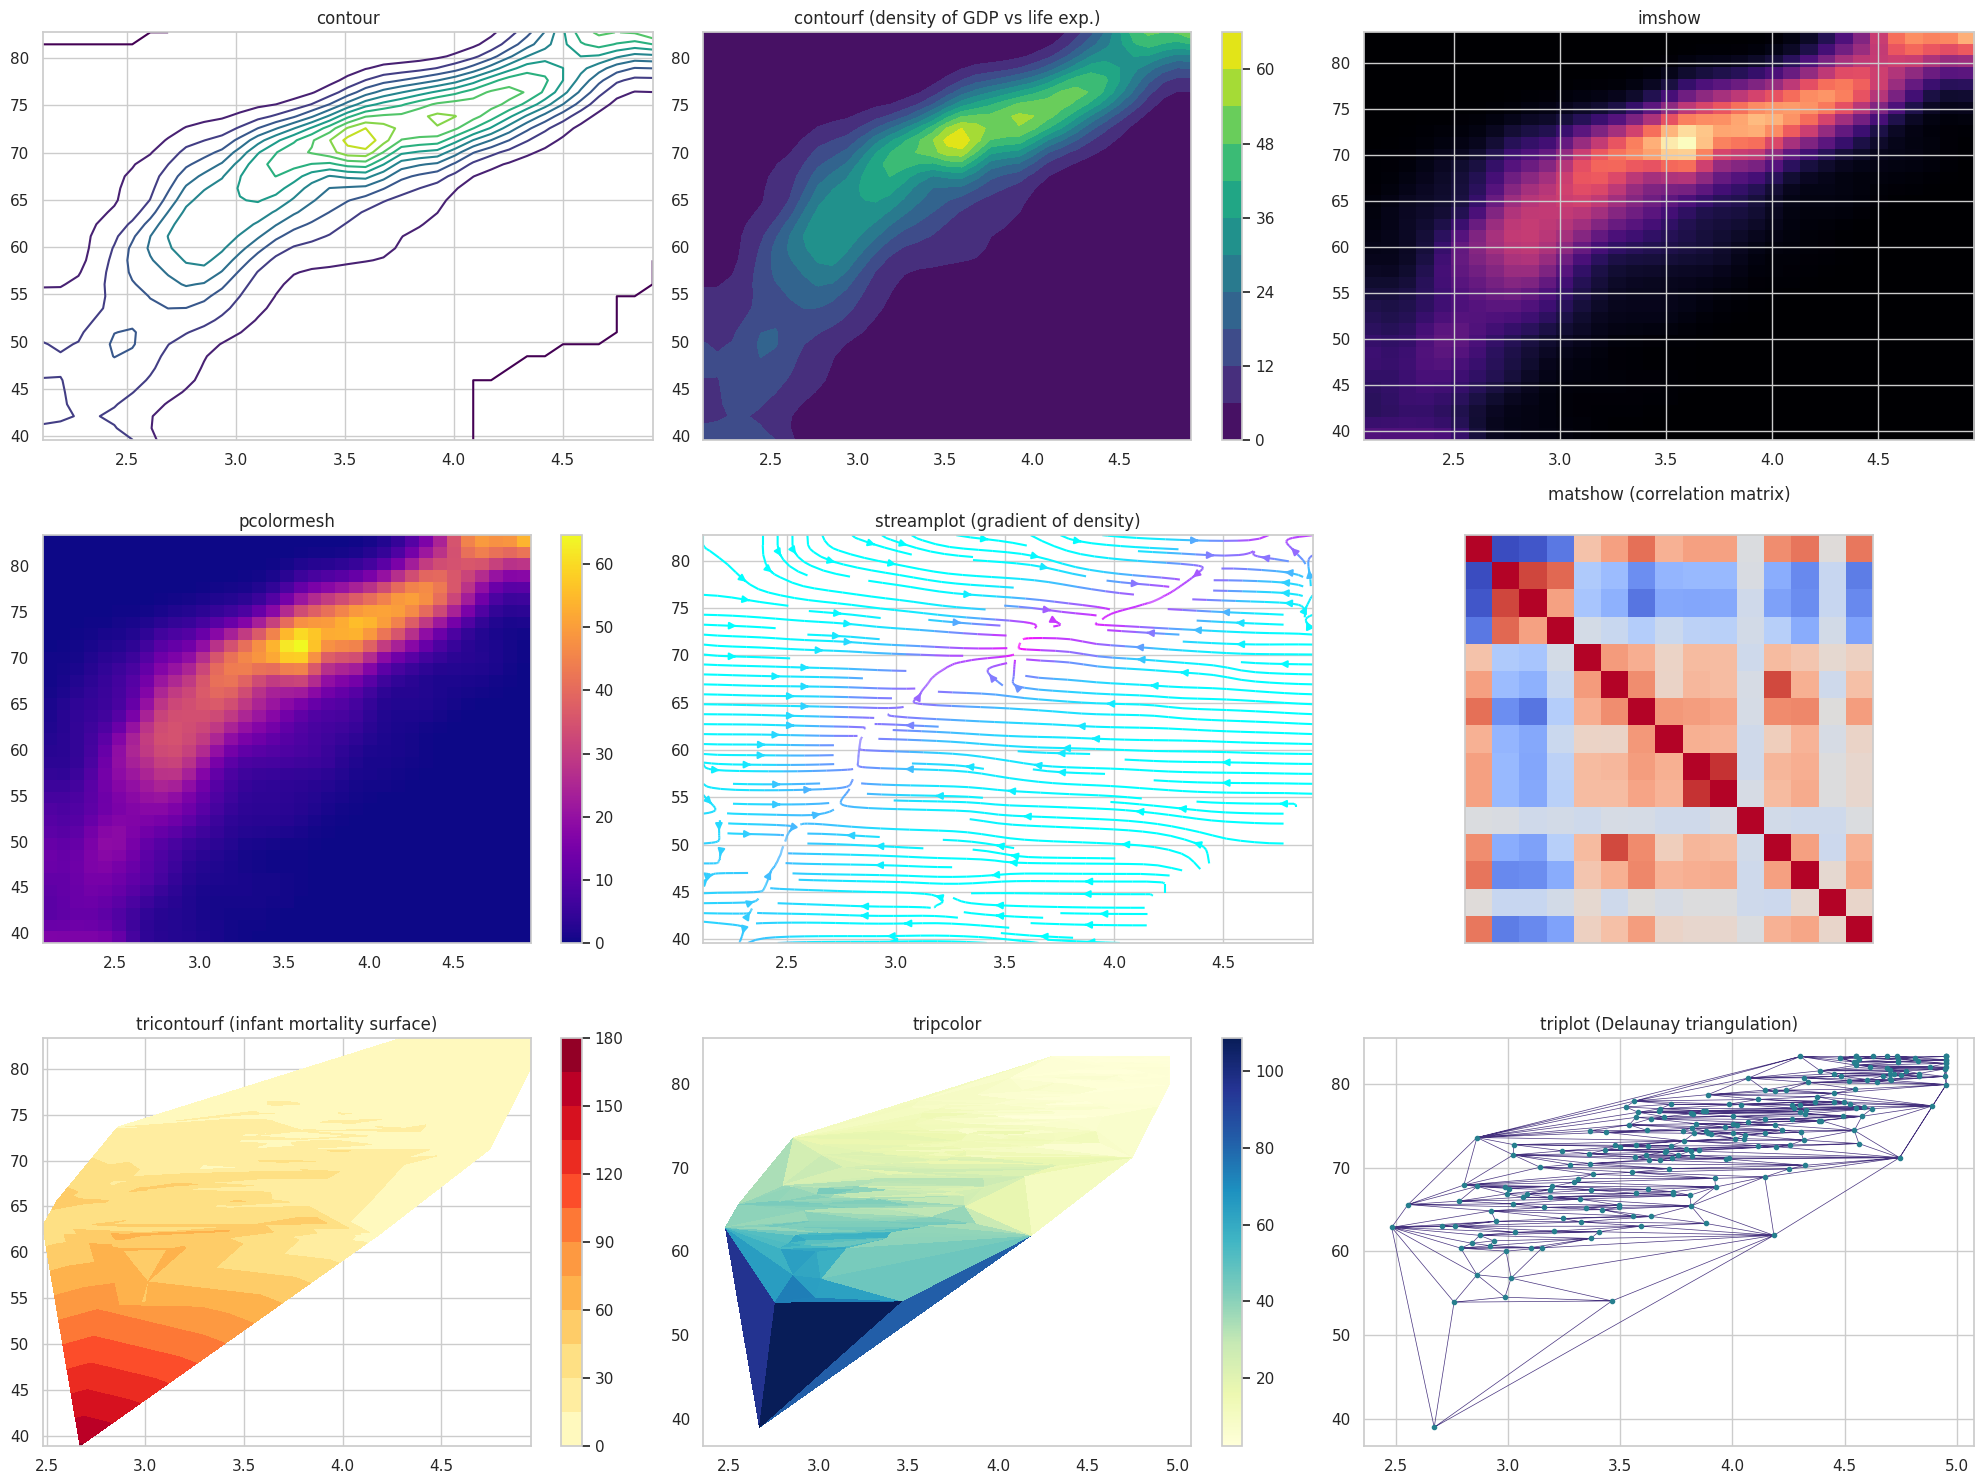

In [ ]:
lg = np.log10(df.gdp_per_capita_usd)
H, xe, ye = np.histogram2d(lg, df.life_expectancy, bins=35); Hs = gaussian_filter(H, 1.2).T
X, Y = np.meshgrid((xe[:-1] + xe[1:]) / 2, (ye[:-1] + ye[1:]) / 2)
tx, ty, tz = np.log10(snap.gdp_per_capita_usd.values), snap.life_expectancy.values, snap.infant_mortality_per_1000.values
from matplotlib.tri import Triangulation
tri = Triangulation(tx, ty)
fig, axes = plt.subplots(3, 3, figsize=(20, 15))
axes[0, 0].contour(X, Y, Hs, levels=10, cmap="viridis"); axes[0, 0].set_title("contour")
c = axes[0, 1].contourf(X, Y, Hs, levels=10, cmap="viridis"); plt.colorbar(c, ax=axes[0, 1]); axes[0, 1].set_title("contourf (density of GDP vs life exp.)")
axes[0, 2].imshow(Hs, origin="lower", aspect="auto", cmap="magma", extent=[xe[0], xe[-1], ye[0], ye[-1]]); axes[0, 2].set_title("imshow")
pm = axes[1, 0].pcolormesh(X, Y, Hs, shading="auto", cmap="plasma"); plt.colorbar(pm, ax=axes[1, 0]); axes[1, 0].set_title("pcolormesh")
U, V = np.gradient(Hs, axis=(1, 0)); axes[1, 1].streamplot(X, Y, U, V, color=Hs, cmap="cool", density=1.4); axes[1, 1].set_title("streamplot (gradient of density)")
axes[1, 2].matshow(df[num_cols].corr(), cmap="coolwarm"); axes[1, 2].set_title("matshow (correlation matrix)", pad=25); axes[1, 2].set_xticks([]); axes[1, 2].set_yticks([])
t = axes[2, 0].tricontourf(tri, tz, levels=10, cmap="YlOrRd"); plt.colorbar(t, ax=axes[2, 0]); axes[2, 0].set_title("tricontourf (infant mortality surface)")
tp = axes[2, 1].tripcolor(tri, tz, cmap="YlGnBu"); plt.colorbar(tp, ax=axes[2, 1]); axes[2, 1].set_title("tripcolor")
axes[2, 2].triplot(tri, lw=.5); axes[2, 2].plot(tx, ty, "o", ms=3); axes[2, 2].set_title("triplot (Delaunay triangulation)")
plt.tight_layout(); plt.show()

### 6.7.6 Matplotlib: Time Series Signal Analysis

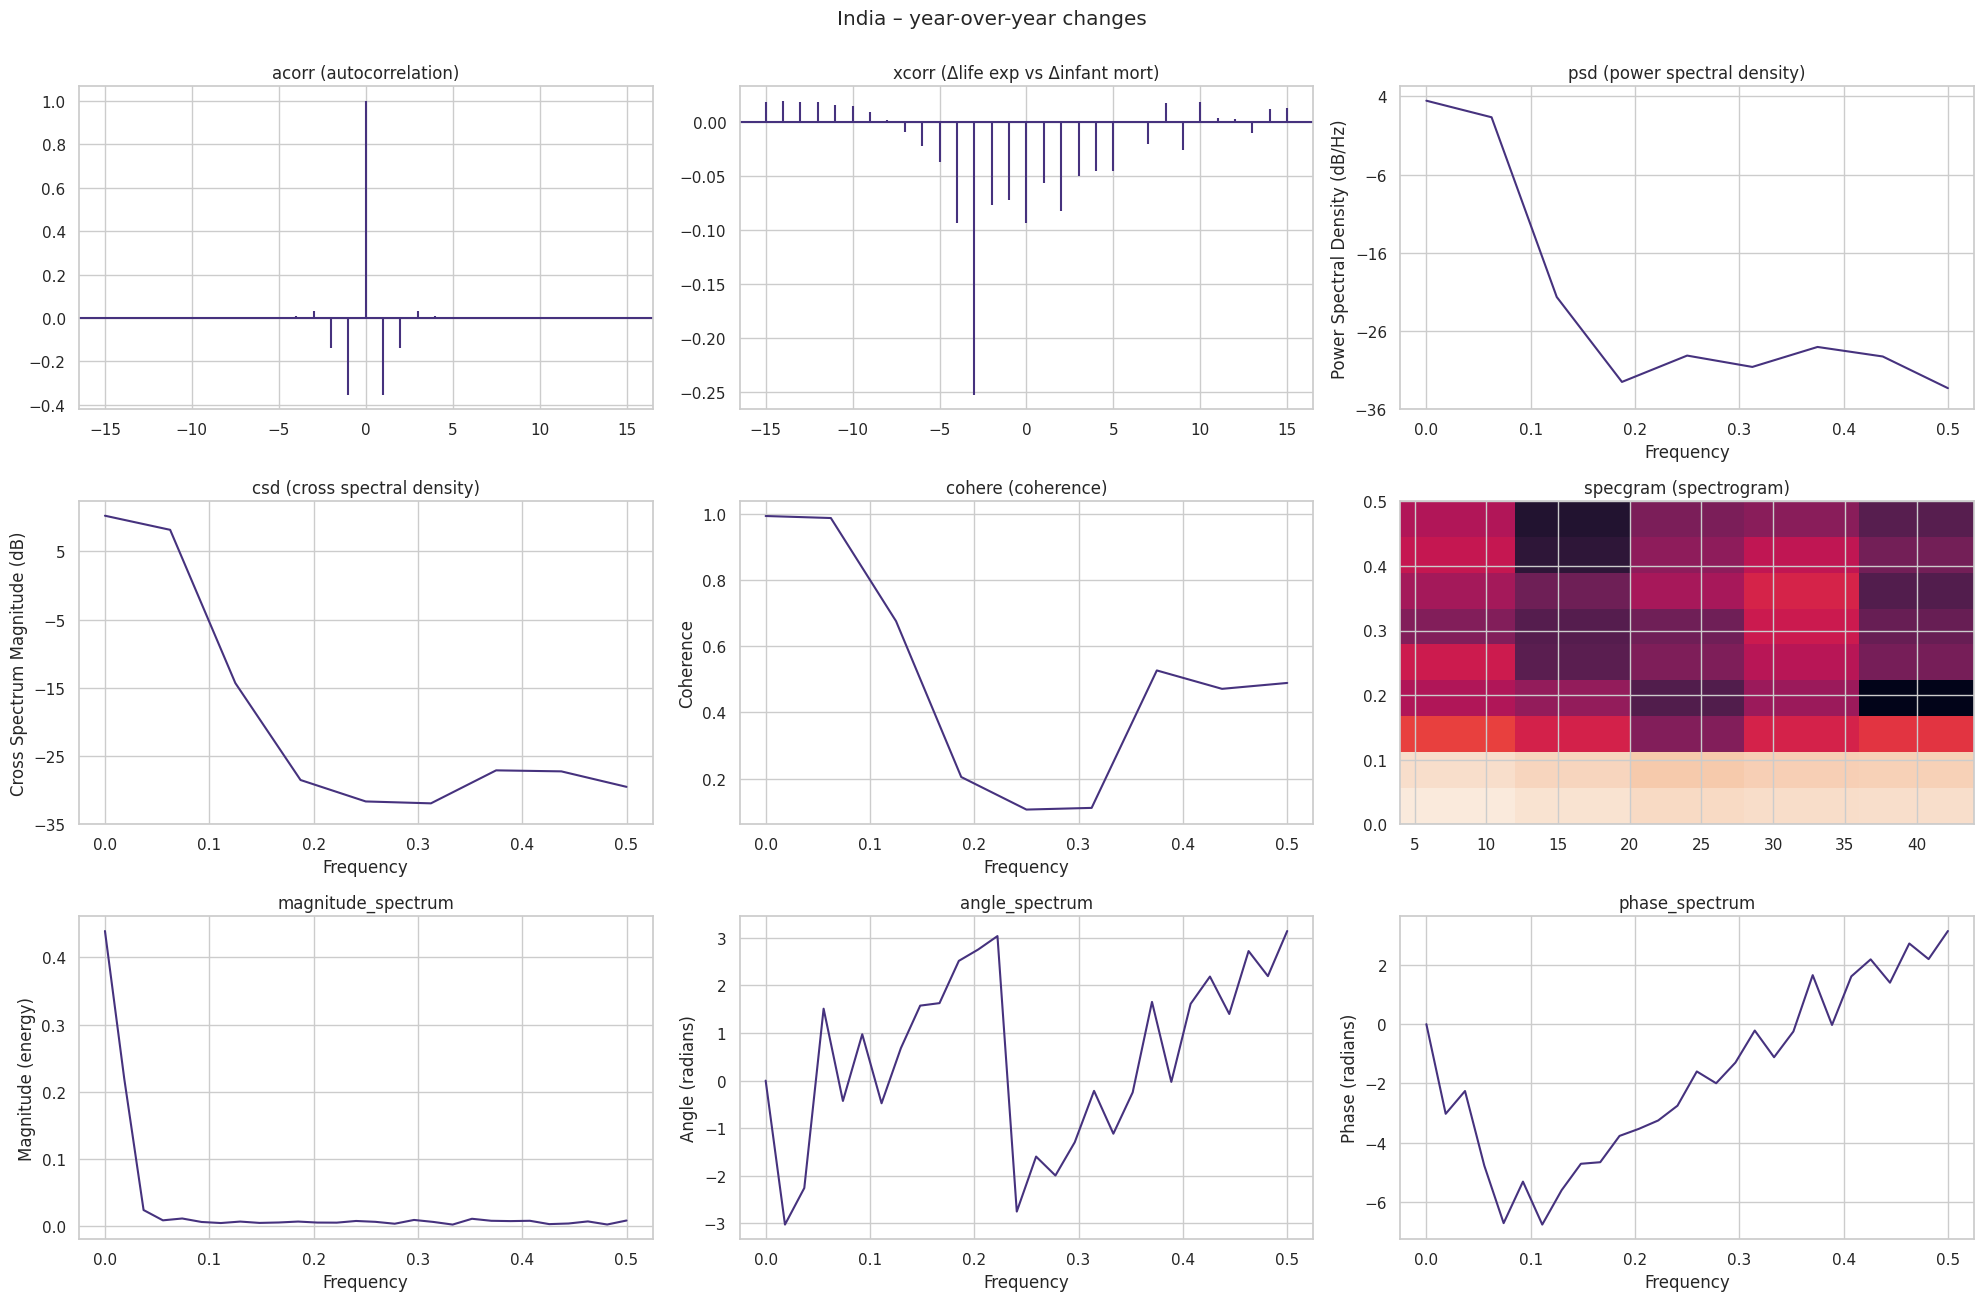

In [ ]:
a = df[df.country == "India"].sort_values("year")
x = np.diff(a.life_expectancy.values); y = np.diff(a.infant_mortality_per_1000.values)   # detrended (first differences)
fig, axes = plt.subplots(3, 3, figsize=(20, 13))
axes[0, 0].acorr(x - x.mean(), maxlags=15); axes[0, 0].set_title("acorr (autocorrelation)")
axes[0, 1].xcorr(x - x.mean(), y - y.mean(), maxlags=15); axes[0, 1].set_title("xcorr (Δlife exp vs Δinfant mort)")
axes[0, 2].psd(x, NFFT=16, Fs=1, noverlap=8); axes[0, 2].set_title("psd (power spectral density)")
axes[1, 0].csd(x, y, NFFT=16, Fs=1, noverlap=8); axes[1, 0].set_title("csd (cross spectral density)")
axes[1, 1].cohere(x, y, NFFT=16, Fs=1, noverlap=8); axes[1, 1].set_title("cohere (coherence)")
axes[1, 2].specgram(x, NFFT=16, Fs=1, noverlap=8); axes[1, 2].set_title("specgram (spectrogram)")
axes[2, 0].magnitude_spectrum(x, Fs=1); axes[2, 0].set_title("magnitude_spectrum")
axes[2, 1].angle_spectrum(x, Fs=1); axes[2, 1].set_title("angle_spectrum")
axes[2, 2].phase_spectrum(x, Fs=1); axes[2, 2].set_title("phase_spectrum")
plt.suptitle("India – year-over-year changes", y=1.0); plt.tight_layout(); plt.show()

### 6.7.7 Matplotlib: Three-Dimensional Visualizations

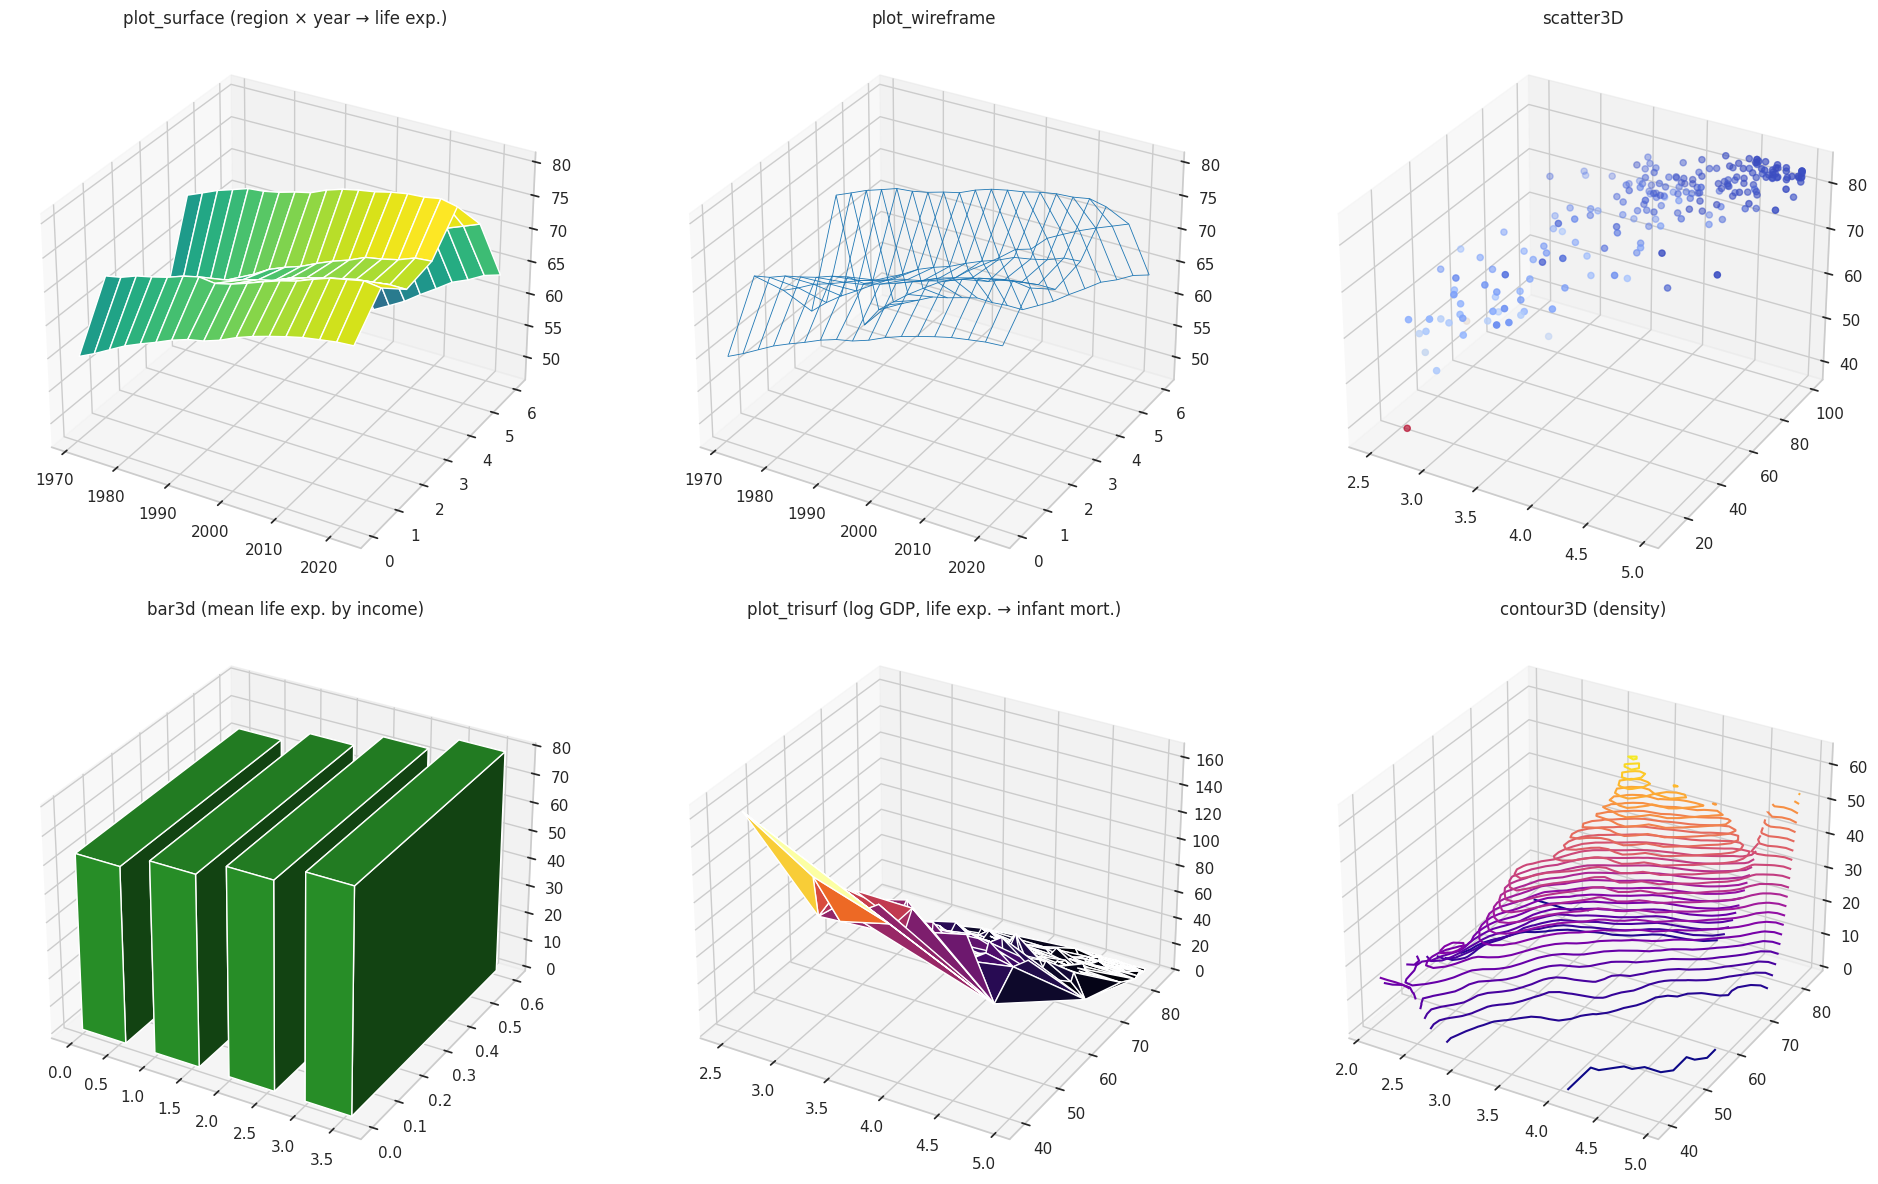

In [ ]:
from mpl_toolkits.mplot3d import Axes3D  # noqa
pv = df[df.year % 3 == 0].pivot_table(index="region", columns="year", values="life_expectancy")
Xg, Yg = np.meshgrid(pv.columns.values, np.arange(len(pv))); Zg = pv.values
fig = plt.figure(figsize=(20, 12))
ax = fig.add_subplot(2, 3, 1, projection="3d"); ax.plot_surface(Xg, Yg, Zg, cmap="viridis"); ax.set_title("plot_surface (region × year → life exp.)")
ax = fig.add_subplot(2, 3, 2, projection="3d"); ax.plot_wireframe(Xg, Yg, Zg, color="tab:blue", lw=.6); ax.set_title("plot_wireframe")
ax = fig.add_subplot(2, 3, 3, projection="3d"); ax.scatter3D(snap.log_gdp if "log_gdp" in snap else np.log10(snap.gdp_per_capita_usd), snap.basic_sanitation_pct,
                                                          snap.life_expectancy, c=snap.infant_mortality_per_1000, cmap="coolwarm"); ax.set_title("scatter3D")
ax = fig.add_subplot(2, 3, 4, projection="3d"); g = snap.groupby("income_group").agg(l=("life_expectancy", "mean"), s=("basic_sanitation_pct", "mean")).reindex(order)
ax.bar3d(np.arange(4), np.zeros(4), np.zeros(4), .6, .6, g.l.values, color="tab:green"); ax.set_title("bar3d (mean life exp. by income)")
ax = fig.add_subplot(2, 3, 5, projection="3d"); ax.plot_trisurf(tx, ty, tz, cmap="inferno"); ax.set_title("plot_trisurf (log GDP, life exp. → infant mort.)")
ax = fig.add_subplot(2, 3, 6, projection="3d"); Xc, Yc = np.meshgrid((xe[:-1] + xe[1:]) / 2, (ye[:-1] + ye[1:]) / 2); ax.contour3D(Xc, Yc, Hs, 25, cmap="plasma"); ax.set_title("contour3D (density)")
plt.tight_layout(); plt.show()

### Summary of Visualization Gallery

This comprehensive gallery demonstrates a wide variety of visualization techniques. We used Seaborn for distribution plots, categorical comparisons, and multi-panel regression grids. We used Matplotlib to construct custom dual-axis line charts, stacked bar charts, contour maps, signal frequency spectrums, and diverse three-dimensional surfaces.

## 7. Feature Engineering

We design and add new features based on domain knowledge to capture relationships in the data:

* Logarithmic transformations for GDP, population, and healthcare expenditure per capita to reduce right skewness.
* Natural increase, calculated as the birth rate minus the death rate.
* Healthcare expenditure relative to GDP, which measures per capita health spending against per capita GDP.
* A numeric time trend representing the number of years elapsed since 1970.
* Year-over-year changes in life expectancy and infant mortality within each country.
* A five-year rolling average of life expectancy to smooth out short-term fluctuations.
* A water and sanitation index, representing the average of sanitation and drinking water access.
* A health capacity index, combining physicians and hospital beds per 1,000 people.
* An interaction term between GDP and urban population percentage.

In [ ]:
df = df.sort_values(["country", "year"]).reset_index(drop=True)
df["log_gdp_per_capita"] = np.log1p(df.gdp_per_capita_usd)
df["log_population"] = np.log1p(df.population)
df["log_health_exp_pc"] = np.log1p(df.health_expenditure_per_capita_usd)
df["natural_increase"] = df.birth_rate_per_1000 - df.death_rate_per_1000
df["health_exp_to_gdp_ratio"] = df.health_expenditure_per_capita_usd / df.gdp_per_capita_usd.replace(0, np.nan)
df["years_since_1970"] = df.year - 1970
g = df.groupby("country")
df["life_exp_yoy_change"] = g.life_expectancy.diff().fillna(0)
df["infant_mort_yoy_change"] = g.infant_mortality_per_1000.diff().fillna(0)
df["life_exp_rolling5"] = g.life_expectancy.transform(lambda s: s.rolling(5, min_periods=1).mean())
df["wash_index"] = (df.basic_sanitation_pct + df.basic_drinking_water_pct) / 2
df["health_capacity_index"] = df.physicians_per_1000 + df.hospital_beds_per_1000
df["gdp_x_urban"] = df.log_gdp_per_capita * df.urban_population_pct / 100
df["health_exp_to_gdp_ratio"] = df.health_exp_to_gdp_ratio.fillna(df.health_exp_to_gdp_ratio.median())

new_feats = ["log_gdp_per_capita","log_population","log_health_exp_pc","natural_increase","health_exp_to_gdp_ratio","years_since_1970",
             "life_exp_yoy_change","infant_mort_yoy_change","life_exp_rolling5","wash_index","health_capacity_index","gdp_x_urban"]
display(df[new_feats].describe().T)
print("Skew before/after log:")
for a, b in [("gdp_per_capita_usd","log_gdp_per_capita"),("population","log_population"),("health_expenditure_per_capita_usd","log_health_exp_pc")]:
    print(f"  {a:35s} {df[a].skew():6.2f} -> {df[b].skew():5.2f}")

,count,mean,std,min,25%,50%,75%,max
log_gdp_per_capita,11915.0,7.961459,1.654980,4.783177,6.593198,7.936726,9.237829,11.406038
log_population,11915.0,14.892511,2.442044,8.641886,13.218254,15.350746,16.568607,21.095475
log_health_exp_pc,11915.0,5.540716,1.376237,2.404647,4.837254,5.602265,6.235379,8.798199
natural_increase,11915.0,16.359377,11.248755,-15.698000,6.555000,16.805000,26.183500,42.040000
health_exp_to_gdp_ratio,11915.0,0.202613,0.369642,0.003593,0.042307,0.068376,0.127145,2.279134
years_since_1970,11915.0,27.029375,15.870520,0.000000,13.000000,27.000000,41.000000,54.000000
life_exp_yoy_change,11915.0,0.271706,1.006372,-19.846000,0.075000,0.257000,0.453659,21.377900
infant_mort_yoy_change,11915.0,-1.021682,3.912389,-105.758000,-1.600000,-0.600000,0.000000,83.158000
life_exp_rolling5,11915.0,66.433120,10.378394,38.953100,60.029900,68.955200,74.002851,83.346341
wash_index,11915.0,83.688353,19.510501,22.642331,84.287281,90.901923,94.952940,100.000000


Skew before/after log:
  gdp_per_capita_usd                    2.79 ->  0.12
  population                            9.46 -> -0.40
  health_expenditure_per_capita_usd     3.49 -> -0.10


In [ ]:
# Do the new features relate to the target?
display(df[new_feats + ["life_expectancy"]].corr()["life_expectancy"].drop("life_expectancy").sort_values().to_frame("corr with life_expectancy").round(2))

,corr with life_expectancy
natural_increase,-0.70
health_exp_to_gdp_ratio,-0.55
log_population,-0.13
life_exp_yoy_change,-0.02
infant_mort_yoy_change,0.10
years_since_1970,0.42
wash_index,0.49
health_capacity_index,0.54
log_health_exp_pc,0.58
gdp_x_urban,0.74


## 8. Feature Binning

We convert continuous variables into discrete categories using four distinct methods:

1. Equal-width binning to divide values into equal intervals.
2. Equal-frequency binning to divide values into quantiles with an equal number of records.
3. Custom binning using established global health thresholds.
4. Machine learning discretizers using uniform, quantile, and k-means clustering strategies.

,life_exp_equal_width,gdp_quantile_bin,infant_mort_risk,era
1970s,0,0,0,2160
1980s,0,0,0,2160
1990s,0,0,0,2170
2000s,0,0,0,2170
2010-24,0,0,0,3255
Q1_poorest,0,2980,0,0
Q2,0,2978,0,0
Q3,0,2978,0,0
Q4_richest,0,2979,0,0
high,4211,0,0,0


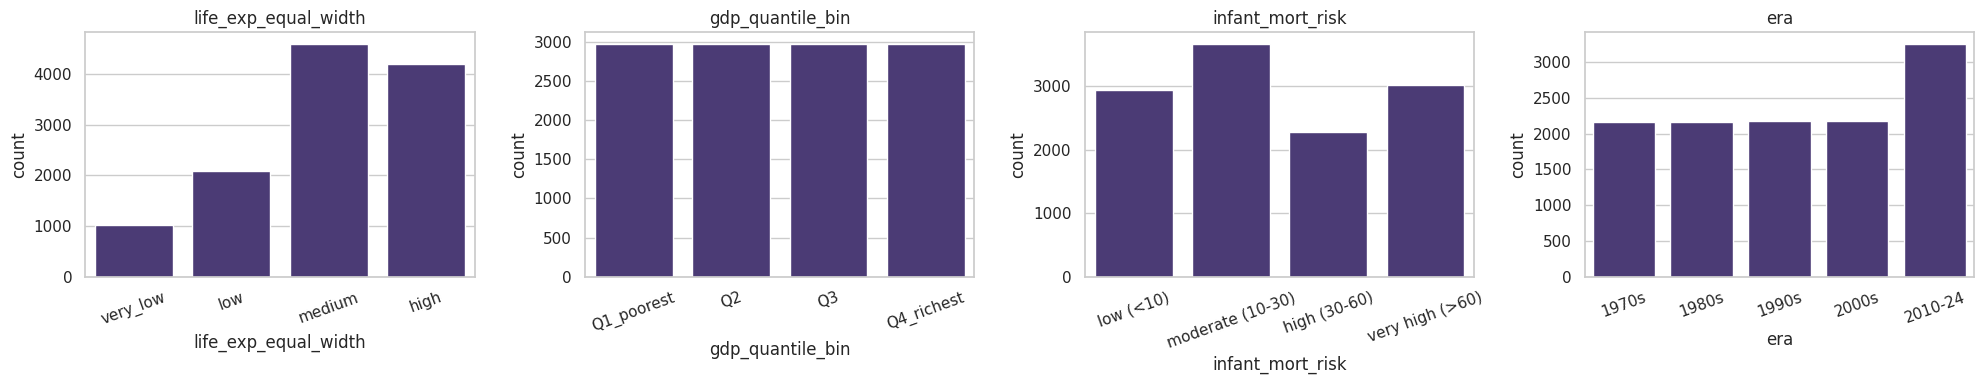

In [ ]:
df["life_exp_equal_width"] = pd.cut(df.life_expectancy, bins=4, labels=["very_low","low","medium","high"])
df["gdp_quantile_bin"] = pd.qcut(df.gdp_per_capita_usd, q=4, labels=["Q1_poorest","Q2","Q3","Q4_richest"])
df["infant_mort_risk"] = pd.cut(df.infant_mortality_per_1000, bins=[-np.inf, 10, 30, 60, np.inf],
                                labels=["low (<10)","moderate (10-30)","high (30-60)","very high (>60)"])
df["era"] = pd.cut(df.year, bins=[1969, 1979, 1989, 1999, 2009, 2024], labels=["1970s","1980s","1990s","2000s","2010-24"])

for strat in ["uniform", "quantile", "kmeans"]:
    kb = KBinsDiscretizer(n_bins=4, encode="ordinal", strategy=strat)
    df[f"urban_kbins_{strat}"] = kb.fit_transform(df[["urban_population_pct"]]).ravel().astype(int)

display(df[["life_exp_equal_width","gdp_quantile_bin","infant_mort_risk","era"]].apply(lambda s: s.value_counts().sort_index()).fillna(0).astype(int))
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, c in zip(axes, ["life_exp_equal_width","gdp_quantile_bin","infant_mort_risk","era"]):
    sns.countplot(data=df, x=c, ax=ax); ax.set_title(c); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

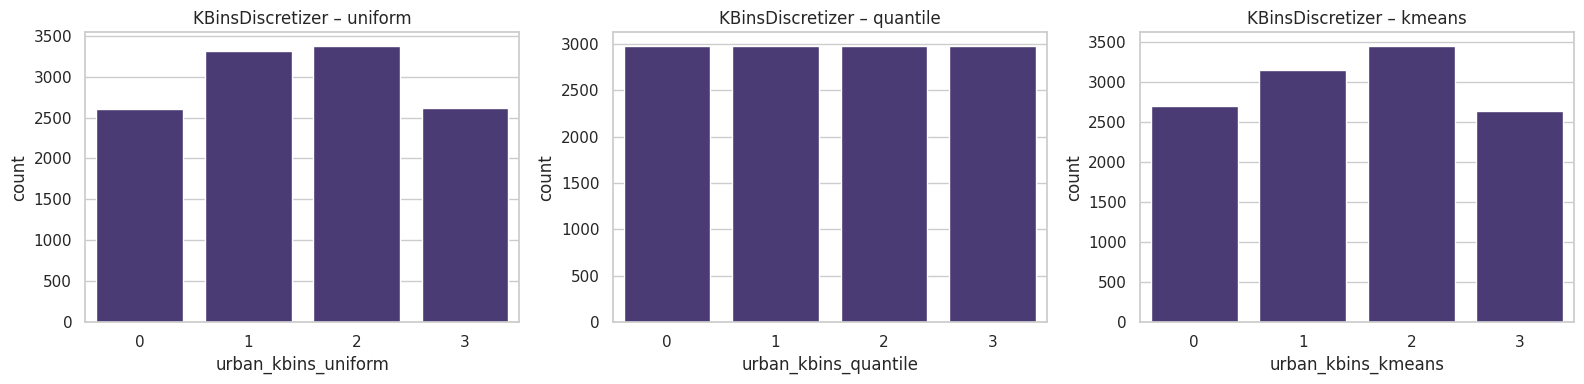

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, s in zip(axes, ["uniform", "quantile", "kmeans"]):
    sns.countplot(x=df[f"urban_kbins_{s}"], ax=ax); ax.set_title(f"KBinsDiscretizer – {s}")
plt.tight_layout(); plt.show()

## 9. Encoding Categorical Variables

We apply appropriate encoding techniques depending on the nature of each categorical variable:

* Ordinal encoding for income groups to preserve their logical order.
* One-hot encoding for geographic regions to avoid implying any mathematical order.
* Frequency and target encoding for country names to handle high-cardinality values.
* Integer mapping for the newly engineered bins.
* Binary encoding to represent high-income countries as 0 or 1.

Note that target encoding uses the target variable and must be calculated within cross-validation folds during predictive modeling to prevent data leakage. We show it here for demonstration purposes.

In [ ]:
income_order = ["Low income", "Lower middle income", "Upper middle income", "High income"]
df["income_ordinal"] = OrdinalEncoder(categories=[income_order]).fit_transform(df[["income_group"]]).astype(int)
df["is_high_income"] = (df.income_group == "High income").astype(int)                       # binary
df["region_label"] = LabelEncoder().fit_transform(df.region)                                 # label (for tree models only)
df["country_freq"] = df.country.map(df.country.value_counts(normalize=True))                # frequency
df["country_target_enc"] = df.groupby("country").life_expectancy.transform("mean")           # target / mean (demo)
for c, order in [("infant_mort_risk", None), ("era", None), ("gdp_quantile_bin", None), ("life_exp_equal_width", None)]:
    df[c + "_code"] = df[c].cat.codes                                                        # ordered bins -> ints
df = pd.concat([df, pd.get_dummies(df.region, prefix="region", dtype=int)], axis=1)         # one-hot
ohe_cols = [c for c in df.columns if c.startswith("region_") and c != "region_label"]
print("One-hot columns:", ohe_cols)
df[["income_group","income_ordinal","is_high_income","region","region_label","country","country_freq","country_target_enc"]].sample(6, random_state=2)

One-hot columns: ['region_East Asia & Pacific', 'region_Europe & Central Asia', 'region_Latin America & Caribbean ', 'region_Middle East, North Africa, Afghanistan & Pakistan', 'region_North America', 'region_South Asia', 'region_Sub-Saharan Africa ']


,income_group,income_ordinal,is_high_income,region,region_label,country,country_freq,country_target_enc
10629,Lower middle income,1,0,East Asia & Pacific,0,Timor-Leste,0.004616,51.839142
11529,Lower middle income,1,0,East Asia & Pacific,0,Vanuatu,0.004616,66.192309
5879,High income,3,1,"Middle East, North Africa, Afghanistan & Pakistan",3,Kuwait,0.004616,75.496909
8984,Upper middle income,2,0,East Asia & Pacific,0,Samoa,0.004616,68.378236
9188,Lower middle income,1,0,Sub-Saharan Africa,6,Senegal,0.004616,57.088636
1237,Lower middle income,1,0,South Asia,5,Bhutan,0.004616,59.487491


## 10. Feature Scaling

We compare several scaling methods on our skewed features. These include StandardScaler, MinMaxScaler, RobustScaler, MaxAbsScaler, and PowerTransformer. In predictive modeling pipelines, you should always fit your scalers on the training data alone and then transform both training and testing datasets to prevent data leakage.

In [ ]:
scale_src = ["gdp_per_capita_usd", "health_expenditure_per_capita_usd", "population", "life_expectancy", "urban_population_pct"]
scalers = {"Original": None, "Standard": StandardScaler(), "MinMax": MinMaxScaler(), "Robust": RobustScaler(),
           "MaxAbs": MaxAbsScaler(), "Yeo-Johnson": PowerTransformer()}
rows = []
for c in scale_src:
    for name, sc in scalers.items():
        x = pd.Series((df[[c]].values if sc is None else sc.fit_transform(df[[c]])).ravel())
        rows.append({"feature": c, "scaler": name, "mean": x.mean(), "std": x.std(), "min": x.min(), "max": x.max(), "skew": x.skew()})
display(pd.DataFrame(rows).set_index(["feature", "scaler"]).round(3))

mean           std  \
feature                           scaler                                    
gdp_per_capita_usd                Original     9.705724e+03  1.639768e+04   
                                  Standard    -0.000000e+00  1.000000e+00   
                                  MinMax       1.070000e-01  1.830000e-01   
                                  Robust       7.240000e-01  1.717000e+00   
                                  MaxAbs       1.080000e-01  1.820000e-01   
                                  Yeo-Johnson -0.000000e+00  1.000000e+00   
health_expenditure_per_capita_usd Original     6.327770e+02  1.121292e+03   
                                  Standard    -0.000000e+00  1.000000e+00   
                                  MinMax       9.400000e-02  1.700000e-01   
                                  Robust       9.440000e-01  2.917000e+00   
                                  MaxAbs       9.600000e-02  1.690000e-01   
                                  Yeo-Johnson -0.000000e+00  1.000000e+00   
population                        Original     2.714283e+07  1.117024e+08   
                                  Standard    -0.000000e+00  1.000000e+00   
                                  MinMax       1.900000e-02  7.700000e-02   
                                  Robust       1.486000e+00  7.378000e+00   
                                  MaxAbs       1.900000e-02  7.700000e-02   
                                  Yeo-Johnson -0.000000e+00  1.000000e+00   
life_expectancy                   Original     6.695400e+01  1.029100e+01   
                                  Standard    -0.000000e+00  1.000000e+00   
                                  MinMax       6.310000e-01  2.320000e-01   
                                  Robust      -1.760000e-01  7.520000e-01   
                                  MaxAbs       8.030000e-01  1.230000e-01   
                                  Yeo-Johnson -0.000000e+00  1.000000e+00   
urban_population_pct              Original     5.428700e+01  2.516800e+01   
                                  Standard    -0.000000e+00  1.000000e+00   
                                  MinMax       5.030000e-01  2.740000e-01   
                                  Robust       1.000000e-03  6.160000e-01   
                                  MaxAbs       5.430000e-01  2.520000e-01   
                                  Yeo-Johnson  0.000000e+00  1.000000e+00   

                                                    min           max   skew  
feature                           scaler                                      
gdp_per_capita_usd                Original      118.483  8.986165e+04  2.787  
                                  Standard       -0.585  4.888000e+00  2.787  
                                  MinMax          0.000  1.000000e+00  2.787  
                                  Robust         -0.281  9.118000e+00  2.787  
                                  MaxAbs          0.001  1.000000e+00  2.787  
                                  Yeo-Johnson    -2.017  1.983000e+00  0.020  
health_expenditure_per_capita_usd Original       10.075  6.621304e+03  3.487  
                                  Standard       -0.555  5.341000e+00  3.487  
                                  MinMax          0.000  1.000000e+00  3.487  
                                  Robust         -0.676  1.652400e+01  3.487  
                                  MaxAbs          0.002  1.000000e+00  3.487  
                                  Yeo-Johnson    -2.213  2.449000e+00  0.001  
population                        Original     5663.000  1.450936e+09  9.457  
                                  Standard       -0.243  1.274700e+01  9.457  
                                  MinMax          0.000  1.000000e+00  9.457  
                                  Robust         -0.306  9.552300e+01  9.457  
                                  MaxAbs          0.000  1.000000e+00  9.457  
                                  Yeo-Johnson    -2.205  3.126000e+00 -0.023  
life_expec

In [ ]:
# apply a final scaling pipeline to every numeric (non-ID, non-binary) feature
scale_cols = num_cols + new_feats
df_scaled = df.copy()
df_scaled[[c + "_std" for c in scale_cols]] = StandardScaler().fit_transform(df[scale_cols])
df_scaled[[c + "_mm" for c in ["gdp_per_capita_usd", "population", "life_expectancy"]]] = MinMaxScaler().fit_transform(
    df[["gdp_per_capita_usd", "population", "life_expectancy"]])
display(df_scaled[[c + "_std" for c in scale_cols[:6]]].describe().loc[["mean", "std", "min", "max"]].round(3))

,life_expectancy_std,infant_mortality_per_1000_std,birth_rate_per_1000_std,death_rate_per_1000_std,health_expenditure_pct_gdp_std,health_expenditure_per_capita_usd_std
mean,-0.000,0.000,-0.000,0.000,0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000
min,-2.721,-0.970,-1.420,-1.614,-2.081,-0.555
max,1.593,3.197,2.061,3.577,3.639,5.341


## 11. Final Dataset Validation and Export

In [ ]:
print("Shape:", df_scaled.shape)
print("Missing values left:", int(df_scaled.isna().sum().sum()))
df.drop(columns=[]).to_csv("data/sdg3_health_engineered.csv", index=False)        # engineered, unscaled (readable)
df_scaled.to_csv("data/sdg3_health_engineered_scaled.csv", index=False)           # + scaled columns (ML-ready)
print(os.listdir("data"))

Shape: (11915, 94)
Missing values left: 0
['sdg3_health_engineered_scaled.csv', 'sdg3_health_engineered.csv', 'sdg3_health_raw.csv']


## Summary and Project Takeaways

* We collected a live dataset of approximately 11,900 country-year records with 20 raw columns from the World Bank API.
* We addressed missing values, which were highly prevalent in healthcare metrics, by using linear interpolation within countries followed by group-based decade medians.
* We identified outliers and treated extreme values by capping them at percentile thresholds, except for population, which we normalized using a logarithmic transformation.
* We engineered 12 domain-specific features, including rolling averages, indexes, and interaction terms.
* We converted continuous variables into discrete bins and applied encoding methods such as one-hot, ordinal, and target encoding.
* Our exploratory plots show that life expectancy and infant mortality rates are strongly associated with country income levels, sanitation access, and healthcare capacity. This highlights the importance of universal healthcare and clean water systems as outlined in the United Nations Sustainable Development Goals.